# Project: Identify Customer Segments

In this project, you will apply unsupervised learning techniques to identify segments of the population that form the core customer base for a mail-order sales company in Germany. These segments can then be used to direct marketing campaigns towards audiences that will have the highest expected rate of returns. The data that you will use has been provided by our partners at Bertelsmann Arvato Analytics, and represents a real-life data science task.

This notebook will help you complete this task by providing a framework within which you will perform your analysis steps. In each step of the project, you will see some text describing the subtask that you will perform, followed by one or more code cells for you to complete your work. **Feel free to add additional code and markdown cells as you go along so that you can explore everything in precise chunks.** The code cells provided in the base template will outline only the major tasks, and will usually not be enough to cover all of the minor tasks that comprise it.

It should be noted that while there will be precise guidelines on how you should handle certain tasks in the project, there will also be places where an exact specification is not provided. **There will be times in the project where you will need to make and justify your own decisions on how to treat the data.** These are places where there may not be only one way to handle the data. In real-life tasks, there may be many valid ways to approach an analysis task. One of the most important things you can do is clearly document your approach so that other scientists can understand the decisions you've made.

At the end of most sections, there will be a Markdown cell labeled **Discussion**. In these cells, you will report your findings for the completed section, as well as document the decisions that you made in your approach to each subtask. **Your project will be evaluated not just on the code used to complete the tasks outlined, but also your communication about your observations and conclusions at each stage.**

In [1]:
# import libraries here; add more as necessary
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# magic word for producing visualizations in notebook
%matplotlib inline

pd.options.display.max_rows = None
pd.options.display.max_columns = None

### Step 0: Load the Data

There are four files associated with this project (not including this one):

- `Udacity_AZDIAS_Subset.csv`: Demographics data for the general population of Germany; 891211 persons (rows) x 85 features (columns).
- `Udacity_CUSTOMERS_Subset.csv`: Demographics data for customers of a mail-order company; 191652 persons (rows) x 85 features (columns).
- `Data_Dictionary.md`: Detailed information file about the features in the provided datasets.
- `AZDIAS_Feature_Summary.csv`: Summary of feature attributes for demographics data; 85 features (rows) x 4 columns

Each row of the demographics files represents a single person, but also includes information outside of individuals, including information about their household, building, and neighborhood. You will use this information to cluster the general population into groups with similar demographic properties. Then, you will see how the people in the customers dataset fit into those created clusters. The hope here is that certain clusters are over-represented in the customers data, as compared to the general population; those over-represented clusters will be assumed to be part of the core userbase. This information can then be used for further applications, such as targeting for a marketing campaign.

To start off with, load in the demographics data for the general population into a pandas DataFrame, and do the same for the feature attributes summary. Note for all of the `.csv` data files in this project: they're semicolon (`;`) delimited, so you'll need an additional argument in your [`read_csv()`](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.read_csv.html) call to read in the data properly. Also, considering the size of the main dataset, it may take some time for it to load completely.

Once the dataset is loaded, it's recommended that you take a little bit of time just browsing the general structure of the dataset and feature summary file. You'll be getting deep into the innards of the cleaning in the first major step of the project, so gaining some general familiarity can help you get your bearings.

In [2]:
# Load in the general demographics data.
azdias = pd.read_csv('Udacity_AZDIAS_Subset.csv', sep=';')

# Load in the feature summary file and store it to a variable
# named `feat_info`.
feat_info = pd.read_csv('AZDIAS_Feature_Summary.csv', sep=';')


In [3]:
# Check the structure of the data after it's loaded (e.g. print the number of
# rows and columns, print the first few rows).
print('azdias shape:', azdias.shape)
print('feat_info shape:', feat_info.shape)
display(azdias.head())
display(feat_info.head())


azdias shape: (891221, 85)
feat_info shape: (85, 4)


,AGER_TYP,ALTERSKATEGORIE_GROB,ANREDE_KZ,CJT_GESAMTTYP,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,FINANZTYP,GEBURTSJAHR,GFK_URLAUBERTYP,GREEN_AVANTGARDE,HEALTH_TYP,LP_LEBENSPHASE_FEIN,LP_LEBENSPHASE_GROB,LP_FAMILIE_FEIN,LP_FAMILIE_GROB,LP_STATUS_FEIN,LP_STATUS_GROB,NATIONALITAET_KZ,PRAEGENDE_JUGENDJAHRE,RETOURTYP_BK_S,SEMIO_SOZ,SEMIO_FAM,SEMIO_REL,SEMIO_MAT,SEMIO_VERT,SEMIO_LUST,SEMIO_ERL,SEMIO_KULT,SEMIO_RAT,SEMIO_KRIT,SEMIO_DOM,SEMIO_KAEM,SEMIO_PFLICHT,SEMIO_TRADV,SHOPPER_TYP,SOHO_KZ,TITEL_KZ,VERS_TYP,ZABEOTYP,ALTER_HH,ANZ_PERSONEN,ANZ_TITEL,HH_EINKOMMEN_SCORE,KK_KUNDENTYP,W_KEIT_KIND_HH,WOHNDAUER_2008,ANZ_HAUSHALTE_AKTIV,ANZ_HH_TITEL,GEBAEUDETYP,KONSUMNAEHE,MIN_GEBAEUDEJAHR,OST_WEST_KZ,WOHNLAGE,CAMEO_DEUG_2015,CAMEO_DEU_2015,CAMEO_INTL_2015,KBA05_ANTG1,KBA05_ANTG2,KBA05_ANTG3,KBA05_ANTG4,KBA05_BAUMAX,KBA05_GBZ,BALLRAUM,EWDICHTE,INNENSTADT,GEBAEUDETYP_RASTER,KKK,MOBI_REGIO,ONLINE_AFFINITAET,REGIOTYP,KBA13_ANZAHL_PKW,PLZ8_ANTG1,PLZ8_ANTG2,PLZ8_ANTG3,PLZ8_ANTG4,PLZ8_BAUMAX,PLZ8_HHZ,PLZ8_GBZ,ARBEIT,ORTSGR_KLS9,RELAT_AB
0,-1,2,1,2.0,3,4,3,5,5,3,4,0,10.0,0,-1,15.0,4.0,2.0,2.0,1.0,1.0,0,0,5.0,2,6,7,5,1,5,3,3,4,7,6,6,5,3,-1,NaN,NaN,-1,3,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1,1,2,5.0,1,5,2,5,4,5,1,1996,10.0,0,3,21.0,6.0,5.0,3.0,2.0,1.0,1,14,1.0,5,4,4,3,1,2,2,3,6,4,7,4,7,6,3,1.0,0.0,2,5,0.0,2.0,0.0,6.0,NaN,3.0,9.0,11.0,0.0,8.0,1.0,1992.0,W,4.0,8,8A,51,0.0,0.0,0.0,2.0,5.0,1.0,6.0,3.0,8.0,3.0,2.0,1.0,3.0,3.0,963.0,2.0,3.0,2.0,1.0,1.0,5.0,4.0,3.0,5.0,4.0
2,-1,3,2,3.0,1,4,1,2,3,5,1,1979,10.0,1,3,3.0,1.0,1.0,1.0,3.0,2.0,1,15,3.0,4,1,3,3,4,4,6,3,4,7,7,7,3,3,2,0.0,0.0,1,5,17.0,1.0,0.0,4.0,NaN,3.0,9.0,10.0,0.0,1.0,5.0,1992.0,W,2.0,4,4C,24,1.0,3.0,1.0,0.0,0.0,3.0,2.0,4.0,4.0,4.0,2.0,3.0,2.0,2.0,712.0,3.0,3.0,1.0,0.0,1.0,4.0,4.0,3.0,5.0,2.0
3,2,4,2,2.0,4,2,5,2,1,2,6,1957,1.0,0,2,0.0,0.0,0.0,0.0,9.0,4.0,1,8,2.0,5,1,2,1,4,4,7,4,3,4,4,5,4,4,1,0.0,0.0,1,3,13.0,0.0,0.0,1.0,NaN,NaN,9.0,1.0,0.0,1.0,4.0,1997.0,W,7.0,2,2A,12,4.0,1.0,0.0,0.0,1.0,4.0,4.0,2.0,6.0,4.0,0.0,4.0,1.0,0.0,596.0,2.0,2.0,2.0,0.0,1.0,3.0,4.0,2.0,3.0,3.0
4,-1,3,1,5.0,4,3,4,1,3,2,5,1963,5.0,0,3,32.0,10.0,10.0,5.0,3.0,2.0,1,8,5.0,6,4,4,2,7,4,4,6,2,3,2,2,4,2,2,0.0,0.0,2,4,20.0,4.0,0.0,5.0,1.0,2.0,9.0,3.0,0.0,1.0,4.0,1992.0,W,3.0,6,6B,43,1.0,4.0,1.0,0.0,0.0,3.0,2.0,5.0,1.0,5.0,3.0,3.0,5.0,5.0,435.0,2.0,4.0,2.0,1.0,2.0,3.0,3.0,4.0,6.0,5.0


,attribute,information_level,type,missing_or_unknown
0,AGER_TYP,person,categorical,"[-1,0]"
1,ALTERSKATEGORIE_GROB,person,ordinal,"[-1,0,9]"
2,ANREDE_KZ,person,categorical,"[-1,0]"
3,CJT_GESAMTTYP,person,categorical,[0]
4,FINANZ_MINIMALIST,person,ordinal,[-1]


> **Tip**: Add additional cells to keep everything in reasonably-sized chunks! Keyboard shortcut `esc --> a` (press escape to enter command mode, then press the 'A' key) adds a new cell before the active cell, and `esc --> b` adds a new cell after the active cell. If you need to convert an active cell to a markdown cell, use `esc --> m` and to convert to a code cell, use `esc --> y`. 

## Step 1: Preprocessing

### Step 1.1: Assess Missing Data

The feature summary file contains a summary of properties for each demographics data column. You will use this file to help you make cleaning decisions during this stage of the project. First of all, you should assess the demographics data in terms of missing data. Pay attention to the following points as you perform your analysis, and take notes on what you observe. Make sure that you fill in the **Discussion** cell with your findings and decisions at the end of each step that has one!

#### Step 1.1.1: Convert Missing Value Codes to NaNs
The fourth column of the feature attributes summary (loaded in above as `feat_info`) documents the codes from the data dictionary that indicate missing or unknown data. While the file encodes this as a list (e.g. `[-1,0]`), this will get read in as a string object. You'll need to do a little bit of parsing to make use of it to identify and clean the data. Convert data that matches a 'missing' or 'unknown' value code into a numpy NaN value. You might want to see how much data takes on a 'missing' or 'unknown' code, and how much data is naturally missing, as a point of interest.

**As one more reminder, you are encouraged to add additional cells to break up your analysis into manageable chunks.**

In [4]:
# Identify missing or unknown data values and convert them to NaNs.
import ast

def parse_missing_codes(code_string):
    """Parse a feat_info `missing_or_unknown` entry into a Python list of codes.

    Entries such as '[-1,0]' parse directly with ast.literal_eval, but entries
    such as '[-1,X]' and '[XX]' contain unquoted strings and need a fallback
    parser.
    """
    code_string = str(code_string).strip()
    if code_string in ('', '[]', 'nan'):
        return []
    try:
        return ast.literal_eval(code_string)
    except (ValueError, SyntaxError):
        codes = []
        for token in code_string.strip('[]').split(','):
            token = token.strip().strip('\'"')
            if token == '':
                continue
            try:
                codes.append(int(token))
            except ValueError:
                codes.append(token)
        return codes

# Map every feature to its list of missing/unknown codes
missing_codes = {row['attribute']: parse_missing_codes(row['missing_or_unknown'])
                 for _, row in feat_info.iterrows()}

nan_before = int(azdias.isna().sum().sum())

for col, codes in missing_codes.items():
    if col not in azdias.columns:
        continue
    for code in codes:
        values = azdias[col]
        if pd.api.types.is_numeric_dtype(values) and not isinstance(code, str):
            azdias.loc[values == code, col] = np.nan
        else:
            azdias.loc[values.astype(str) == str(code), col] = np.nan

# Special cases that must be handled explicitly:
azdias.loc[azdias['GEBURTSJAHR'] == 0, 'GEBURTSJAHR'] = np.nan                    # 0 = missing
azdias.loc[azdias['ANZ_HAUSHALTE_AKTIV'] == 0, 'ANZ_HAUSHALTE_AKTIV'] = np.nan    # 0 = missing
azdias.loc[azdias['MIN_GEBAEUDEJAHR'] == 0, 'MIN_GEBAEUDEJAHR'] = np.nan          # 0 = missing
azdias.loc[azdias['CAMEO_DEUG_2015'].astype(str) == 'X', 'CAMEO_DEUG_2015'] = np.nan
azdias.loc[azdias['CAMEO_DEU_2015'].astype(str) == 'XX', 'CAMEO_DEU_2015'] = np.nan
azdias.loc[azdias['CAMEO_INTL_2015'].astype(str) == 'XX', 'CAMEO_INTL_2015'] = np.nan

nan_after = int(azdias.isna().sum().sum())
print('NaNs before code conversion: {}'.format(nan_before))
print('NaNs after  code conversion: {} ({} values newly converted to NaN)\n'.format(
    nan_after, nan_after - nan_before))
print('Count of NaNs per column after conversion:')
print(azdias.isna().sum())


NaNs before code conversion: 4896838
NaNs after  code conversion: 8373929 (3477091 values newly converted to NaN)

Count of NaNs per column after conversion:
AGER_TYP                 685843
ALTERSKATEGORIE_GROB       2881
ANREDE_KZ                     0
CJT_GESAMTTYP              4854
FINANZ_MINIMALIST             0
FINANZ_SPARER                 0
FINANZ_VORSORGER              0
FINANZ_ANLEGER                0
FINANZ_UNAUFFAELLIGER         0
FINANZ_HAUSBAUER              0
FINANZTYP                     0
GEBURTSJAHR              392318
GFK_URLAUBERTYP            4854
GREEN_AVANTGARDE              0
HEALTH_TYP               111196
LP_LEBENSPHASE_FEIN       97632
LP_LEBENSPHASE_GROB       94572
LP_FAMILIE_FEIN           77792
LP_FAMILIE_GROB           77792
LP_STATUS_FEIN             4854
LP_STATUS_GROB             4854
NATIONALITAET_KZ         108315
PRAEGENDE_JUGENDJAHRE    108164
RETOURTYP_BK_S             4854
SEMIO_SOZ                     0
SEMIO_FAM                     0
SEMIO_REL 

#### Step 1.1.2: Assess Missing Data in Each Column

How much missing data is present in each column? There are a few columns that are outliers in terms of the proportion of values that are missing. You will want to use matplotlib's [`hist()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html) function to visualize the distribution of missing value counts to find these columns. Identify and document these columns. While some of these columns might have justifications for keeping or re-encoding the data, for this project you should just remove them from the dataframe. (Feel free to make remarks about these outlier columns in the discussion, however!)

For the remaining features, are there any patterns in which columns have, or share, missing data?

In [5]:
# Perform an assessment of how much missing data there is in each column of the
# dataset.
missing_per_col = azdias.isna().mean().sort_values(ascending=False)
print('Percentage of missing values per column:')
print((missing_per_col * 100).round(2))


Percentage of missing values per column:
TITEL_KZ                 99.76
AGER_TYP                 76.96
KK_KUNDENTYP             65.60
KBA05_BAUMAX             53.47
GEBURTSJAHR              44.02
ALTER_HH                 34.81
KKK                      17.74
REGIOTYP                 17.74
W_KEIT_KIND_HH           16.61
KBA05_ANTG1              14.96
KBA05_GBZ                14.96
KBA05_ANTG2              14.96
KBA05_ANTG3              14.96
KBA05_ANTG4              14.96
MOBI_REGIO               14.96
PLZ8_ANTG2               13.07
PLZ8_ANTG3               13.07
PLZ8_BAUMAX              13.07
PLZ8_ANTG4               13.07
PLZ8_HHZ                 13.07
PLZ8_GBZ                 13.07
PLZ8_ANTG1               13.07
SHOPPER_TYP              12.48
HEALTH_TYP               12.48
VERS_TYP                 12.48
NATIONALITAET_KZ         12.15
PRAEGENDE_JUGENDJAHRE    12.14
KBA13_ANZAHL_PKW         11.87
ANZ_HAUSHALTE_AKTIV      11.18
CAMEO_DEU_2015           11.15
CAMEO_INTL_2015          11.1

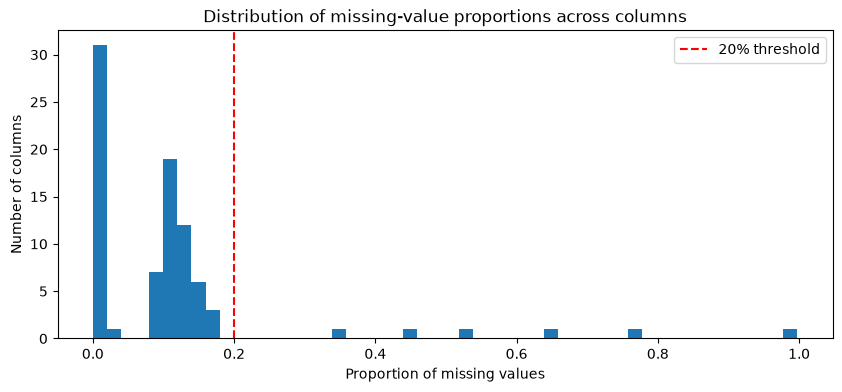

Columns with more than 20% missing values:


TITEL_KZ        99.76
AGER_TYP        76.96
KK_KUNDENTYP    65.60
KBA05_BAUMAX    53.47
GEBURTSJAHR     44.02
ALTER_HH        34.81
dtype: float64


In [6]:
# Investigate patterns in the amount of missing data in each column.
plt.figure(figsize=(10, 4))
plt.hist(missing_per_col, bins=50)
plt.axvline(0.20, color='red', linestyle='--', label='20% threshold')
plt.xlabel('Proportion of missing values')
plt.ylabel('Number of columns')
plt.title('Distribution of missing-value proportions across columns')
plt.legend()
plt.show()

print('Columns with more than 20% missing values:')
print((missing_per_col[missing_per_col > 0.20] * 100).round(2))


In [7]:
# Remove the outlier columns from the dataset. (You'll perform other data
# engineering tasks such as re-encoding and imputation later.)
cols_to_drop = missing_per_col[missing_per_col > 0.20].index.tolist()
azdias.drop(columns=cols_to_drop, inplace=True)
print('Dropped {} columns (>20% missing):'.format(len(cols_to_drop)))
print(cols_to_drop)
print('azdias shape after dropping outlier columns:', azdias.shape)


Dropped 6 columns (>20% missing):
['TITEL_KZ', 'AGER_TYP', 'KK_KUNDENTYP', 'KBA05_BAUMAX', 'GEBURTSJAHR', 'ALTER_HH']
azdias shape after dropping outlier columns: (891221, 79)


#### Discussion 1.1.2: Assess Missing Data in Each Column

The distribution of per-column missingness is strongly bimodal: the bulk of the features have almost no missing values (well under 5%), while a small group of six columns sits far to the right of the histogram. Using a **20% missing-value threshold**, the following outlier columns were dropped (stored in `cols_to_drop`):

| Column | % missing | Meaning |
|---|---|---|
| TITEL_KZ | 99.8% | Academic title flag |
| AGER_TYP | 77.0% | Best-ager typology |
| KK_KUNDENTYP | 65.6% | Consumer pattern over past 12 months |
| KBA05_BAUMAX | 53.5% | Most common building type within the microcell |
| GEBURTSJAHR | 44.0% | Year of birth |
| ALTER_HH | 34.8% | Birthdate of head of household |

Two clear patterns emerge in the missing data. First, several groups of columns share *exactly* the same missing percentage, which indicates entire survey modules being skipped together: the RR3 microcell block (`KBA05_ANTG1`-`KBA05_ANTG4`, `KBA05_GBZ`, all 14.96%, together with `MOBI_REGIO`), the PLZ8 macro-cell block (`PLZ8_ANTG1`-`PLZ8_ANTG4`, `PLZ8_BAUMAX`, `PLZ8_GBZ`, `PLZ8_HHZ`, all 13.07%), the person-level insurance/shopper block (`HEALTH_TYP`, `VERS_TYP`, `SHOPPER_TYP`, all 12.48%), and the region block (`KKK`/`REGIOTYP`, both 17.74%). Second, five of the six dropped columns are optional person- or household-level questions (academic title, best-ager class, consumer pattern, birth year, household birthdate) that respondents can decline; the sixth (`KBA05_BAUMAX`) is missing exactly where the whole microcell module was not surveyed. This module-wise co-missingness foreshadows the row-level analysis in 1.1.3: rows that miss one feature of a module tend to miss all of them. After the drop, 79 of the original 85 columns remain.


#### Step 1.1.3: Assess Missing Data in Each Row

Now, you'll perform a similar assessment for the rows of the dataset. How much data is missing in each row? As with the columns, you should see some groups of points that have a very different numbers of missing values. Divide the data into two subsets: one for data points that are above some threshold for missing values, and a second subset for points below that threshold.

In order to know what to do with the outlier rows, we should see if the distribution of data values on columns that are not missing data (or are missing very little data) are similar or different between the two groups. Select at least five of these columns and compare the distribution of values.
- You can use seaborn's [`countplot()`](https://seaborn.pydata.org/generated/seaborn.countplot.html) function to create a bar chart of code frequencies and matplotlib's [`subplot()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.subplot.html) function to put bar charts for the two subplots side by side.
- To reduce repeated code, you might want to write a function that can perform this comparison, taking as one of its arguments a column to be compared.

Depending on what you observe in your comparison, this will have implications on how you approach your conclusions later in the analysis. If the distributions of non-missing features look similar between the data with many missing values and the data with few or no missing values, then we could argue that simply dropping those points from the analysis won't present a major issue. On the other hand, if the data with many missing values looks very different from the data with few or no missing values, then we should make a note on those data as special. We'll revisit these data later on. **Either way, you should continue your analysis for now using just the subset of the data with few or no missing values.**

count    891221.000000
mean          5.649894
std          13.234687
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          49.000000
dtype: float64

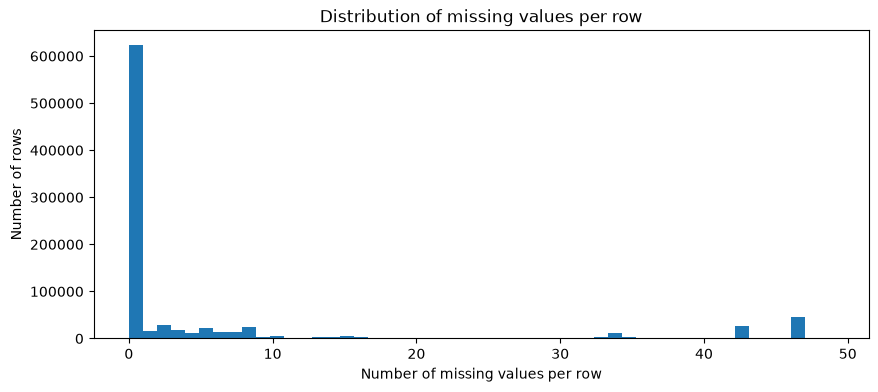

In [8]:
# How much data is missing in each row of the dataset?
missing_per_row = azdias.isna().sum(axis=1)
print(missing_per_row.describe())

plt.figure(figsize=(10, 4))
plt.hist(missing_per_row, bins=50)
plt.xlabel('Number of missing values per row')
plt.ylabel('Number of rows')
plt.title('Distribution of missing values per row')
plt.show()


In [9]:
# Write code to divide the data into two subsets based on the number of missing
# values in each row.
ROW_MISSING_THRESHOLD = 15

azdias_clean = azdias[missing_per_row <= ROW_MISSING_THRESHOLD].copy()
azdias_outliers = azdias[missing_per_row > ROW_MISSING_THRESHOLD].copy()

print('Rows with <= {} missing values: {:,} ({:.1f}%)'.format(
    ROW_MISSING_THRESHOLD, azdias_clean.shape[0], 100 * azdias_clean.shape[0] / azdias.shape[0]))
print('Rows with >  {} missing values: {:,} ({:.1f}%)'.format(
    ROW_MISSING_THRESHOLD, azdias_outliers.shape[0], 100 * azdias_outliers.shape[0] / azdias.shape[0]))
outlier_counts = missing_per_row[missing_per_row > ROW_MISSING_THRESHOLD]
print('Missing counts among outlier rows: min={:.0f}, median={:.0f}, max={:.0f}'.format(
    outlier_counts.min(), outlier_counts.median(), outlier_counts.max()))


Rows with <= 15 missing values: 792,287 (88.9%)
Rows with >  15 missing values: 98,934 (11.1%)
Missing counts among outlier rows: min=16, median=43, max=49


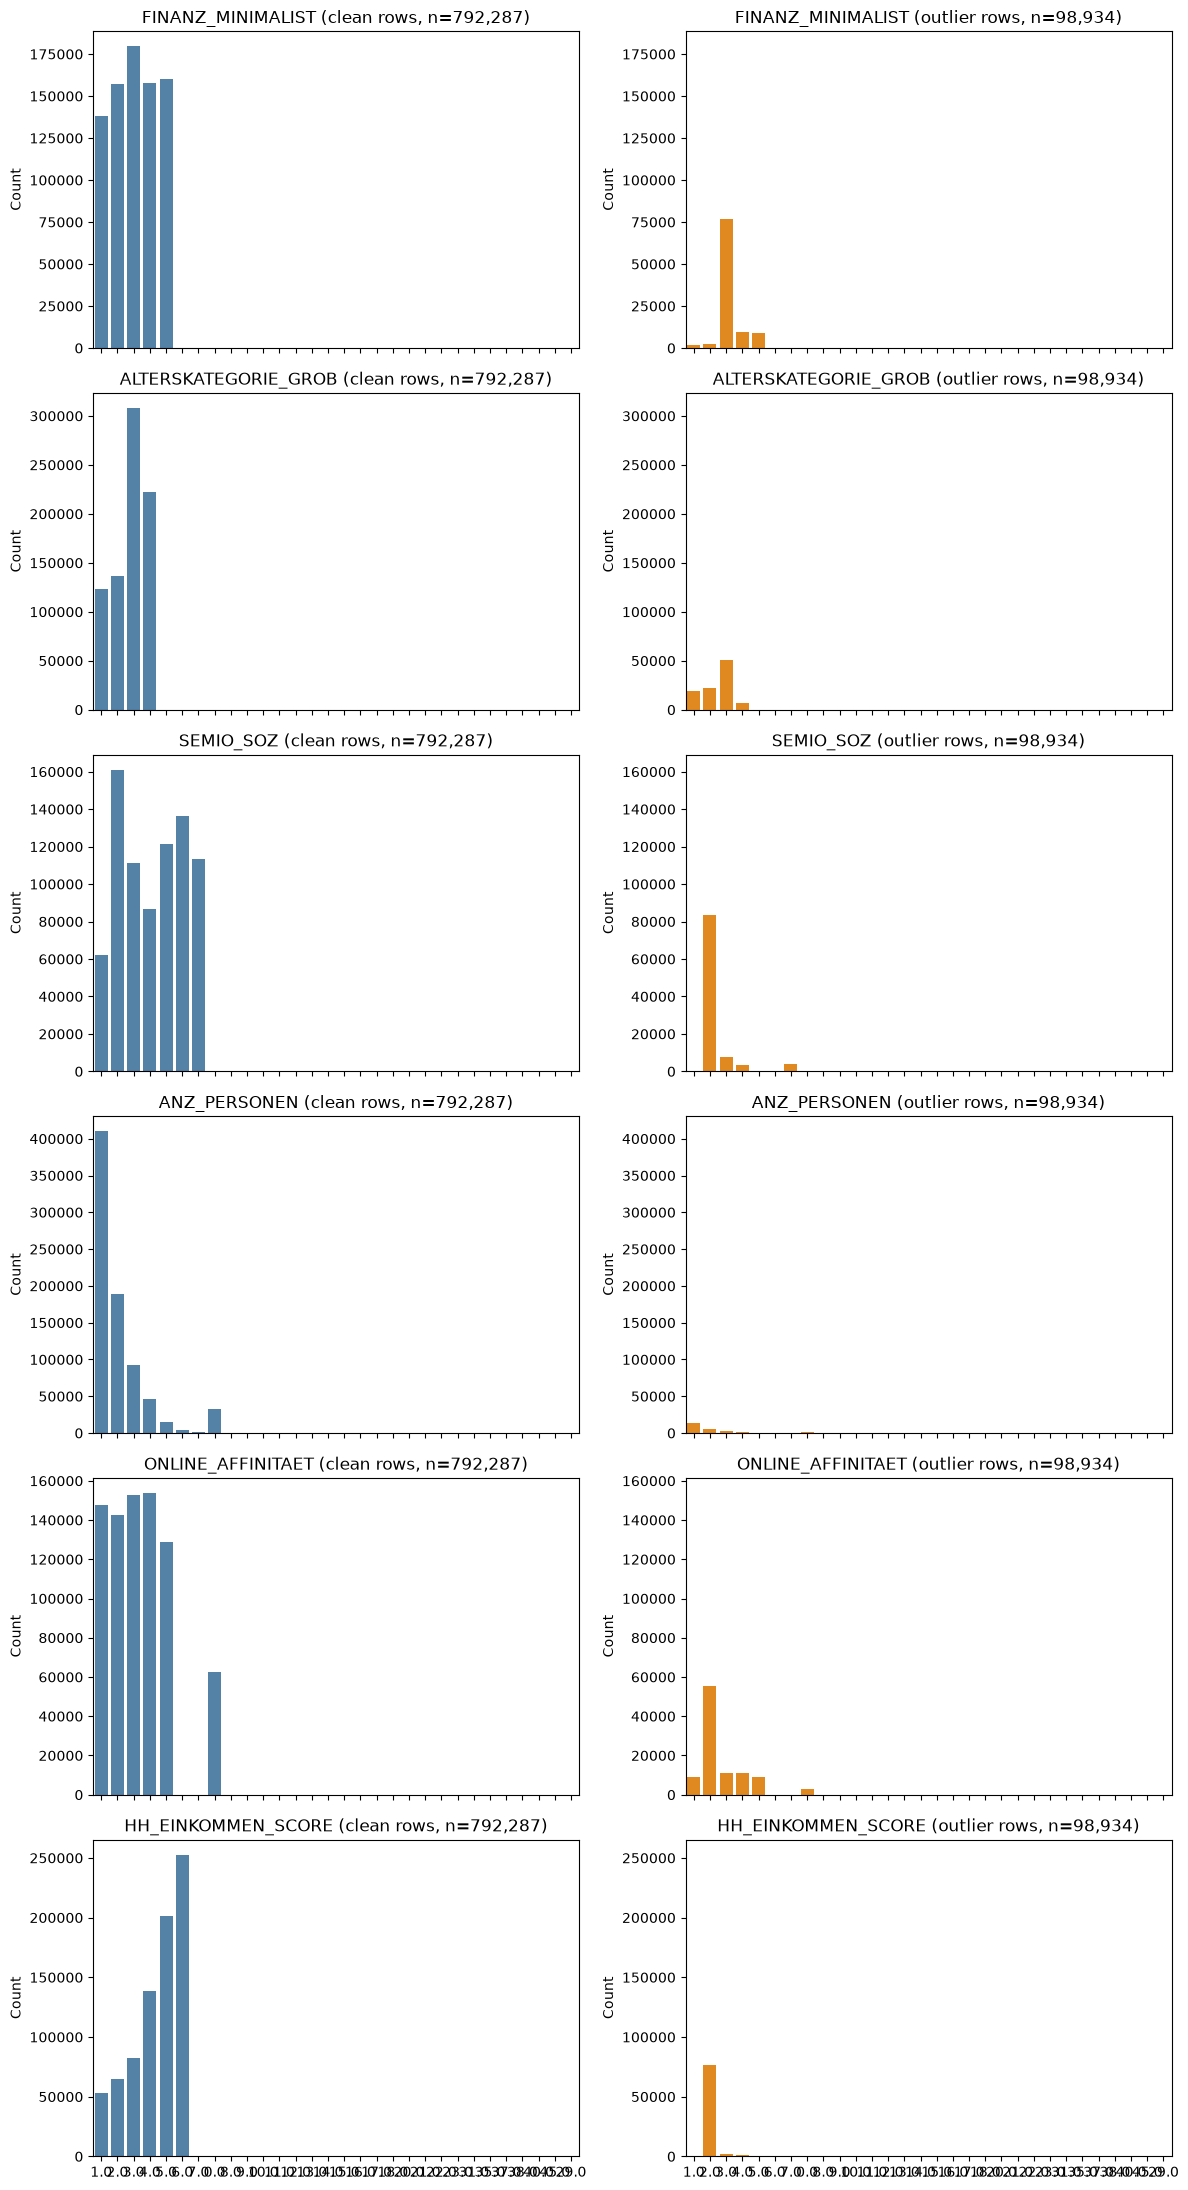

                      clean_mean  outlier_mean  clean_%missing  \
FINANZ_MINIMALIST          3.057         3.218           0.000   
ALTERSKATEGORIE_GROB       2.796         2.448           0.346   
SEMIO_SOZ                  4.146         2.346           0.000   
ANZ_PERSONEN               1.731         1.626           0.000   
ONLINE_AFFINITAET          2.728         2.461           0.551   
HH_EINKOMMEN_SCORE         4.423         2.082           0.000   

                      outlier_%missing  
FINANZ_MINIMALIST                0.000  
ALTERSKATEGORIE_GROB             0.143  
SEMIO_SOZ                        0.000  
ANZ_PERSONEN                    74.291  
ONLINE_AFFINITAET                0.491  
HH_EINKOMMEN_SCORE              18.546  


In [10]:
# Compare the distribution of values for at least five columns where there are
# no or few missing values, between the two subsets.
compare_cols = ['FINANZ_MINIMALIST', 'ALTERSKATEGORIE_GROB', 'SEMIO_SOZ',
                'ANZ_PERSONEN', 'ONLINE_AFFINITAET', 'HH_EINKOMMEN_SCORE']

fig, axes = plt.subplots(len(compare_cols), 2, figsize=(12, 22), sharex=True)

for row, col in enumerate(compare_cols):
    sns.countplot(data=azdias_clean, x=col, ax=axes[row, 0], color='steelblue')
    axes[row, 0].set_title('{} (clean rows, n={:,})'.format(col, azdias_clean.shape[0]))
    axes[row, 0].set_xlabel('')
    axes[row, 0].set_ylabel('Count')

    sns.countplot(data=azdias_outliers, x=col, ax=axes[row, 1], color='darkorange')
    axes[row, 1].set_title('{} (outlier rows, n={:,})'.format(col, azdias_outliers.shape[0]))
    axes[row, 1].set_xlabel('')
    axes[row, 1].set_ylabel('Count')

    # share the y-scale so both magnitude and shape are comparable
    ymax = max(axes[row, 0].get_ylim()[1], axes[row, 1].get_ylim()[1])
    axes[row, 0].set_ylim(0, ymax)
    axes[row, 1].set_ylim(0, ymax)

plt.tight_layout()
plt.show()

# numeric summary to support the visual comparison
summary = pd.DataFrame({
    'clean_mean': azdias_clean[compare_cols].mean(),
    'outlier_mean': azdias_outliers[compare_cols].mean(),
    'clean_%missing': 100 * azdias_clean[compare_cols].isna().mean(),
    'outlier_%missing': 100 * azdias_outliers[compare_cols].isna().mean()}).round(3)
print(summary)


#### Discussion 1.1.3: Assess Missing Data in Each Row

The per-row missing-value distribution is bimodal. Around 81% of rows have 5 or fewer missing values (75th percentile = 3, mean = 5.65), while a second group of roughly 11% of rows carries 34-49 missing values (the 90th percentile jumps all the way to 34). The valley between the modes is nearly empty: only ~8% of rows have 6-15 missing values, and only ~0.7% have 16-32. I therefore chose a threshold of **15 missing values per row**: it sits in the empty valley, so virtually any threshold between 15 and 32 would produce the same split, and 15 is a conservative round number. This yields `azdias_clean` with 792,287 rows (88.9% of the data) and `azdias_outliers` with 98,934 rows (11.1%), whose missing counts range from 16 to 49 (median 43).

The outlier rows are *qualitatively different* from the main data, not just noisier. Among the near-complete person-level features shown above, the outliers are younger (mean ALTERSKATEGORIE_GROB 2.45 vs. 2.80), markedly more socially-minded (SEMIO_SOZ 2.35 vs. 4.15; on this scale 1 = highest affinity), more online-affine (ONLINE_AFFINITAET 2.46 vs. 2.73), and substantially higher-income (HH_EINKOMMEN_SCORE 2.08 vs. 4.42, where 1 = highest income), while their financial typology is similar (FINANZ_MINIMALIST 3.22 vs. 3.06). Just as important is what they lack: MOBI_REGIO is missing for 99.7% of the outlier rows, RELAT_AB for 94.2%, and ANZ_PERSONEN for 74.3% - these respondents skipped entire household and regional survey modules, and that non-response is correlated with their demographics. Because the missingness is systematic rather than random, dropping this group removes a younger, wealthier, more socially-conscious niche from the population baseline. All subsequent analysis therefore uses only `azdias_clean`, and this limitation is revisited in the final discussion: 11.1% of the population is not represented by any cluster.


### Step 1.2: Select and Re-Encode Features

Checking for missing data isn't the only way in which you can prepare a dataset for analysis. Since the unsupervised learning techniques to be used will only work on data that is encoded numerically, you need to make a few encoding changes or additional assumptions to be able to make progress. In addition, while almost all of the values in the dataset are encoded using numbers, not all of them represent numeric values. Check the third column of the feature summary (`feat_info`) for a summary of types of measurement.
- For numeric and interval data, these features can be kept without changes.
- Most of the variables in the dataset are ordinal in nature. While ordinal values may technically be non-linear in spacing, make the simplifying assumption that the ordinal variables can be treated as being interval in nature (that is, kept without any changes).
- Special handling may be necessary for the remaining two variable types: categorical, and 'mixed'.

In the first two parts of this sub-step, you will perform an investigation of the categorical and mixed-type features and make a decision on each of them, whether you will keep, drop, or re-encode each. Then, in the last part, you will create a new data frame with only the selected and engineered columns.

Data wrangling is often the trickiest part of the data analysis process, and there's a lot of it to be done here. But stick with it: once you're done with this step, you'll be ready to get to the machine learning parts of the project!

In [11]:
# How many features are there of each data type?
print(feat_info['type'].value_counts())
print('\nCategorical features:')
print(feat_info.loc[feat_info['type'] == 'categorical', 'attribute'].tolist())
print('\nMixed features:')
print(feat_info.loc[feat_info['type'] == 'mixed', 'attribute'].tolist())


type
ordinal        49
categorical    21
numeric         7
mixed           7
interval        1
Name: count, dtype: int64

Categorical features:
['AGER_TYP', 'ANREDE_KZ', 'CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP', 'GREEN_AVANTGARDE', 'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP', 'SOHO_KZ', 'TITEL_KZ', 'VERS_TYP', 'ZABEOTYP', 'KK_KUNDENTYP', 'GEBAEUDETYP', 'OST_WEST_KZ', 'CAMEO_DEUG_2015', 'CAMEO_DEU_2015']

Mixed features:
['LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB', 'PRAEGENDE_JUGENDJAHRE', 'WOHNLAGE', 'CAMEO_INTL_2015', 'KBA05_BAUMAX', 'PLZ8_BAUMAX']


#### Step 1.2.1: Re-Encode Categorical Features

For categorical data, you would ordinarily need to encode the levels as dummy variables. Depending on the number of categories, perform one of the following:
- For binary (two-level) categoricals that take numeric values, you can keep them without needing to do anything.
- There is one binary variable that takes on non-numeric values. For this one, you need to re-encode the values as numbers or create a dummy variable.
- For multi-level categoricals (three or more values), you can choose to encode the values using multiple dummy variables (e.g. via [OneHotEncoder](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)), or (to keep things straightforward) just drop them from the analysis. As always, document your choices in the Discussion section.

In [12]:
# Assess categorical variables: which are binary, which are multi-level, and
# which one needs to be re-encoded?
categorical_cols = feat_info.loc[feat_info['type'] == 'categorical', 'attribute'].tolist()

for col in categorical_cols:
    if col not in azdias_clean.columns:
        print('{:20s} -> already removed (high missingness)'.format(col))
        continue
    n_levels = azdias_clean[col].nunique()
    levels = sorted(azdias_clean[col].dropna().astype(str).unique().tolist())
    kind = 'binary' if n_levels == 2 else 'multi-level'
    print('{:20s} -> {:12s} n={:2d} levels={}'.format(col, kind, n_levels, levels))

# Binary, already numerically encoded -> keep as-is
binary_numeric_cats = ['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP']

# Binary, string encoded -> needs re-encoding (handled in the next cell)
binary_string_cats = ['OST_WEST_KZ']

# Multi-level (3+ values) -> drop from the analysis
multi_level_cats = ['CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN',
                    'LP_FAMILIE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB',
                    'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP',
                    'CAMEO_DEU_2015', 'CAMEO_DEUG_2015', 'GEBAEUDETYP']

print('\nBinary kept as-is:', binary_numeric_cats)
print('Binary to re-encode:', binary_string_cats)
print('Multi-level to drop ({}):'.format(len(multi_level_cats)), multi_level_cats)


AGER_TYP             -> already removed (high missingness)
ANREDE_KZ            -> binary       n= 2 levels=['1.0', '2.0']


CJT_GESAMTTYP        -> multi-level  n= 6 levels=['1.0', '2.0', '3.0', '4.0', '5.0', '6.0']
FINANZTYP            -> multi-level  n= 6 levels=['1.0', '2.0', '3.0', '4.0', '5.0', '6.0']


GFK_URLAUBERTYP      -> multi-level  n=12 levels=['1.0', '10.0', '11.0', '12.0', '2.0', '3.0', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0']
GREEN_AVANTGARDE     -> binary       n= 2 levels=['0', '1']


LP_FAMILIE_FEIN      -> multi-level  n=11 levels=['1.0', '10.0', '11.0', '2.0', '3.0', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0']
LP_FAMILIE_GROB      -> multi-level  n= 5 levels=['1.0', '2.0', '3.0', '4.0', '5.0']


LP_STATUS_FEIN       -> multi-level  n=10 levels=['1.0', '10.0', '2.0', '3.0', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0']
LP_STATUS_GROB       -> multi-level  n= 5 levels=['1.0', '2.0', '3.0', '4.0', '5.0']


NATIONALITAET_KZ     -> multi-level  n= 3 levels=['1.0', '2.0', '3.0']
SHOPPER_TYP          -> multi-level  n= 4 levels=['0.0', '1.0', '2.0', '3.0']


SOHO_KZ              -> binary       n= 2 levels=['0.0', '1.0']
TITEL_KZ             -> already removed (high missingness)
VERS_TYP             -> binary       n= 2 levels=['1.0', '2.0']


ZABEOTYP             -> multi-level  n= 6 levels=['1.0', '2.0', '3.0', '4.0', '5.0', '6.0']
KK_KUNDENTYP         -> already removed (high missingness)
GEBAEUDETYP          -> multi-level  n= 7 levels=['1.0', '2.0', '3.0', '4.0', '5.0', '6.0', '8.0']
OST_WEST_KZ          -> binary       n= 2 levels=['O', 'W']
CAMEO_DEUG_2015      -> multi-level  n= 9 levels=['1', '2', '3', '4', '5', '6', '7', '8', '9']
CAMEO_DEU_2015       -> multi-level  n=44 levels=['1A', '1B', '1C', '1D', '1E', '2A', '2B', '2C', '2D', '3A', '3B', '3C', '3D', '4A', '4B', '4C', '4D', '4E', '5A', '5B', '5C', '5D', '5E', '5F', '6A', '6B', '6C', '6D', '6E', '6F', '7A', '7B', '7C', '7D', '7E', '8A', '8B', '8C', '8D', '9A', '9B', '9C', '9D', '9E']

Binary kept as-is: ['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP']
Binary to re-encode: ['OST_WEST_KZ']
Multi-level to drop (13): ['CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB', 'NATIONALITAET_KZ

In [13]:
# Re-encode categorical variable(s) to be kept in the analysis.
OST_WEST_MAP = {'W': 1, 'O': 0}   # West Germany = 1, East Germany = 0
azdias_clean['OST_WEST_KZ'] = azdias_clean['OST_WEST_KZ'].map(OST_WEST_MAP).astype(float)
print(azdias_clean['OST_WEST_KZ'].value_counts(dropna=False))


OST_WEST_KZ
1.0    624737
0.0    167550
Name: count, dtype: int64


#### Discussion 1.2.1: Re-Encode Categorical Features

Of the 21 categorical features in `feat_info`, three (AGER_TYP, TITEL_KZ, KK_KUNDENTYP) had already been removed in step 1.1.2 for excessive missingness. The remaining 18 were handled as follows:

- **Kept as-is (binary, already numeric):** ANREDE_KZ (1 = male / 2 = female), GREEN_AVANTGARDE (0/1), SOHO_KZ (0/1), and VERS_TYP (1/2). Each has exactly two numeric levels and can be consumed directly by the downstream algorithms.
- **Re-encoded (binary, string-typed):** OST_WEST_KZ, whose values 'W' (West Germany) and 'O' (East Germany) were mapped to 1 and 0 respectively via `OST_WEST_MAP`.
- **Dropped (multi-level, 3 or more values):** 13 features stored in `multi_level_cats` - CJT_GESAMTTYP (6 levels), FINANZTYP (6), GFK_URLAUBERTYP (12), LP_FAMILIE_FEIN (11), LP_FAMILIE_GROB (5), LP_STATUS_FEIN (10), LP_STATUS_GROB (5), NATIONALITAET_KZ (3), SHOPPER_TYP (4), ZABEOTYP (6), GEBAEUDETYP (7), CAMEO_DEUG_2015 (9), and CAMEO_DEU_2015 (44).

The multi-level features were dropped rather than one-hot encoded in order to keep the feature space compact: one-hot encoding them would add roughly 120 dummy columns - nearly 90 of them from CAMEO_DEU_2015 alone - and those sparse indicators would dominate the Euclidean distances that drive both PCA and k-means. Several of the dropped features are also coarser duplicates of finer variants of themselves (LP_FAMILIE_GROB is contained in LP_FAMILIE_FEIN; LP_STATUS_GROB in LP_STATUS_FEIN), or substantially overlap with information that is re-engineered from CAMEO_INTL_2015 (CAMEO_DEUG_2015/CAMEO_DEU_2015), so relatively little signal is lost by dropping them.


#### Step 1.2.2: Engineer Mixed-Type Features

There are a handful of features that are marked as "mixed" in the feature summary that require special treatment in order to be included in the analysis. There are two in particular that deserve attention; the handling of the rest are up to your own choices:
- "PRAEGENDE_JUGENDJAHRE" combines information on three dimensions: generation by decade, movement (mainstream vs. avantgarde), and nation (east vs. west). While there aren't enough levels to disentangle east from west, you should create two new variables to capture the other two dimensions: an interval-type variable for decade, and a binary variable for movement.
- "CAMEO_INTL_2015" combines information on two axes: wealth and life stage. Break up the two-digit codes by their 'tens'-place and 'ones'-place digits into two new ordinal variables (which, for the purposes of this project, is equivalent to just treating them as their raw numeric values).
- If you decide to keep or engineer new features around the other mixed-type features, make sure you note your steps in the Discussion section.

Be sure to check `Data_Dictionary.md` for the details needed to finish these tasks.

In [14]:
# Investigate "PRAEGENDE_JUGENDJAHRE" and engineer two new variables.
DECADE_MAP = {1: 40, 2: 40, 3: 50, 4: 50, 5: 60, 6: 60, 7: 60,
              8: 70, 9: 70, 10: 80, 11: 80, 12: 80, 13: 80, 14: 90, 15: 90}
MOVEMENT_MAP = {1: 0, 2: 1, 3: 0, 4: 1, 5: 0, 6: 1, 7: 1, 8: 0, 9: 1,
                10: 0, 11: 1, 12: 0, 13: 1, 14: 0, 15: 1}   # 0 = mainstream, 1 = avantgarde

azdias_clean['DECADE'] = azdias_clean['PRAEGENDE_JUGENDJAHRE'].map(DECADE_MAP)
azdias_clean['MOVEMENT'] = azdias_clean['PRAEGENDE_JUGENDJAHRE'].map(MOVEMENT_MAP)

print('DECADE distribution (decade of youth):')
print(azdias_clean['DECADE'].value_counts().sort_index())
print('\nMOVEMENT distribution (0 = mainstream, 1 = avantgarde):')
print(azdias_clean['MOVEMENT'].value_counts().sort_index())

azdias_clean.drop(columns=['PRAEGENDE_JUGENDJAHRE'], inplace=True)


DECADE distribution (decade of youth):
DECADE
40.0     28020
50.0     74046
60.0    114029
70.0    174196
80.0    150778
90.0    223603
Name: count, dtype: int64

MOVEMENT distribution (0 = mainstream, 1 = avantgarde):
MOVEMENT
0.0    590387
1.0    174285
Name: count, dtype: int64


In [15]:
# Investigate "CAMEO_INTL_2015" and engineer two new variables.
cam = azdias_clean['CAMEO_INTL_2015'].astype(str)
azdias_clean['WEALTH'] = pd.to_numeric(cam.str[0], errors='coerce')      # tens digit: 1 = wealthy ... 5 = poorer
azdias_clean['LIFE_STAGE'] = pd.to_numeric(cam.str[1], errors='coerce')  # ones digit: 1 = pre-family ... 5 = retired
azdias_clean.loc[azdias_clean['CAMEO_INTL_2015'].isna(), ['WEALTH', 'LIFE_STAGE']] = np.nan

print('WEALTH distribution (1 = wealthy households ... 5 = poorer households):')
print(azdias_clean['WEALTH'].value_counts().sort_index())
print('\nLIFE_STAGE distribution (1 = pre-family couples/singles ... 5 = elders in retirement):')
print(azdias_clean['LIFE_STAGE'].value_counts().sort_index())

azdias_clean.drop(columns=['CAMEO_INTL_2015'], inplace=True)


WEALTH distribution (1 = wealthy households ... 5 = poorer households):
WEALTH
1.0    118776
2.0    189071
3.0     67582
4.0    189389
5.0    223153
Name: count, dtype: int64

LIFE_STAGE distribution (1 = pre-family couples/singles ... 5 = elders in retirement):
LIFE_STAGE
1.0    244233
2.0     76879
3.0    118541
4.0    231772
5.0    116546
Name: count, dtype: int64


#### Discussion 1.2.2: Engineer Mixed-Type Features

**PRAEGENDE_JUGENDJAHRE** (15 codes combining a decade, a mainstream/avantgarde movement, and an east/west dimension) was split into two clean features using explicit dictionaries:

- `DECADE` (interval): codes 1-2 to the 40s, 3-4 to the 50s, 5-7 to the 60s, 8-9 to the 70s, 10-13 to the 80s, and 14-15 to the 90s.
- `MOVEMENT` (binary): mainstream to 0, avantgarde to 1 (e.g., 1 to 0, 2 to 1, 6 to 1, 14 to 0).

The east/west dimension is not separately encoded, since the data dictionary does not allow disentangling it for every code, and the original column was dropped after engineering so its raw 1-15 coding would not interfere with the analysis.

**CAMEO_INTL_2015** (a two-digit string whose tens digit encodes wealth and ones digit encodes life stage) was split digit-wise into two ordinal features: `WEALTH` = tens digit (1 = wealthy households ... 5 = poorer households) and `LIFE_STAGE` = ones digit (1 = pre-family couples & singles ... 5 = elders in retirement). The conversion is NaN-safe: the column is cast to string, digits are extracted with `.str[0]`/`.str[1]`, and `pd.to_numeric(..., errors='coerce')` maps any non-numeric leftovers (including the stringified NaN) back to NaN; rows that were NaN in CAMEO_INTL_2015 are then explicitly set to NaN in both new columns. The original column was dropped.

**Other mixed features:** LP_LEBENSPHASE_FEIN (40 levels) and LP_LEBENSPHASE_GROB (12 levels) were dropped - they encode life stage on too many levels to be usefully retained as raw ordinals, and their information is largely covered by the new WEALTH/LIFE_STAGE pair together with household-level features. WOHNAGE and PLZ8_BAUMAX are flagged "mixed" in `feat_info` but are in fact integer-coded ordinals once missing-value codes are converted (no string levels remain), so they were kept as numeric features under the usual simplifying assumption that ordinal codes behave like interval data. KBA05_BAUMAX, the last mixed feature, had already been removed for missingness in step 1.1.2.


#### Step 1.2.3: Complete Feature Selection

In order to finish this step up, you need to make sure that your data frame now only has the columns that you want to keep. To summarize, the dataframe should consist of the following:
- All numeric, interval, and ordinal type columns from the original dataset.
- Binary categorical features (all numerically-encoded).
- Engineered features from other multi-level categorical features and mixed features.

Make sure that for any new columns that you have engineered, that you've excluded the original columns from the final dataset. Otherwise, their values will interfere with the analysis later on the project. For example, you should not keep "PRAEGENDE_JUGENDJAHRE", since its values won't be useful for the algorithm: only the values derived from it in the engineered features you created should be retained. As a reminder, your data should only be from **the subset with few or no missing values**.

In [16]:
# If there are other re-engineering tasks you need to perform, make sure you
# take care of them here. (Dealing with missing data will come in step 2.1.)
mixed_originals = ['LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB']
# PRAEGENDE_JUGENDJAHRE and CAMEO_INTL_2015 were already dropped after engineering.

# cols_to_drop columns were removed from `azdias` back in step 1.1.2, so only the
# multi-level categoricals and the remaining mixed originals need to go here.
columns_to_remove = set(multi_level_cats) | set(mixed_originals)
present_to_remove = [c for c in columns_to_remove if c in azdias_clean.columns]
azdias_clean.drop(columns=present_to_remove, inplace=True)
print('Removed {} columns here:'.format(len(present_to_remove)))
print(sorted(present_to_remove))


Removed 15 columns here:
['CAMEO_DEUG_2015', 'CAMEO_DEU_2015', 'CJT_GESAMTTYP', 'FINANZTYP', 'GEBAEUDETYP', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP']


In [17]:
# Do whatever you need to in order to ensure that the dataframe only contains
# the columns that should be passed to the algorithm functions.
azdias_final = azdias_clean.copy()

# Defensive: make sure none of the high-missingness columns from 1.1.2 survive.
azdias_final.drop(columns=[c for c in cols_to_drop if c in azdias_final.columns], inplace=True)

print('azdias_final shape:', azdias_final.shape)
non_numeric = azdias_final.select_dtypes(exclude=[np.number]).columns.tolist()
print('Non-numeric columns remaining:', non_numeric)
print('Maximum missing share in any column: {:.2f}%'.format(100 * azdias_final.isna().mean().max()))
display(azdias_final.head())


azdias_final shape: (792287, 66)
Non-numeric columns remaining: []
Maximum missing share in any column: 7.62%


,ALTERSKATEGORIE_GROB,ANREDE_KZ,FINANZ_MINIMALIST,FINANZ_SPARER,FINANZ_VORSORGER,FINANZ_ANLEGER,FINANZ_UNAUFFAELLIGER,FINANZ_HAUSBAUER,GREEN_AVANTGARDE,HEALTH_TYP,RETOURTYP_BK_S,SEMIO_SOZ,SEMIO_FAM,SEMIO_REL,SEMIO_MAT,SEMIO_VERT,SEMIO_LUST,SEMIO_ERL,SEMIO_KULT,SEMIO_RAT,SEMIO_KRIT,SEMIO_DOM,SEMIO_KAEM,SEMIO_PFLICHT,SEMIO_TRADV,SOHO_KZ,VERS_TYP,ANZ_PERSONEN,ANZ_TITEL,HH_EINKOMMEN_SCORE,W_KEIT_KIND_HH,WOHNDAUER_2008,ANZ_HAUSHALTE_AKTIV,ANZ_HH_TITEL,KONSUMNAEHE,MIN_GEBAEUDEJAHR,OST_WEST_KZ,WOHNLAGE,KBA05_ANTG1,KBA05_ANTG2,KBA05_ANTG3,KBA05_ANTG4,KBA05_GBZ,BALLRAUM,EWDICHTE,INNENSTADT,GEBAEUDETYP_RASTER,KKK,MOBI_REGIO,ONLINE_AFFINITAET,REGIOTYP,KBA13_ANZAHL_PKW,PLZ8_ANTG1,PLZ8_ANTG2,PLZ8_ANTG3,PLZ8_ANTG4,PLZ8_BAUMAX,PLZ8_HHZ,PLZ8_GBZ,ARBEIT,ORTSGR_KLS9,RELAT_AB,DECADE,MOVEMENT,WEALTH,LIFE_STAGE
1,1.0,2.0,1.0,5.0,2.0,5.0,4.0,5.0,0,3.0,1.0,5.0,4.0,4.0,3.0,1.0,2.0,2.0,3.0,6.0,4.0,7.0,4.0,7.0,6.0,1.0,2.0,2.0,0.0,6.0,3.0,9.0,11.0,0.0,1.0,1992.0,1.0,4.0,0.0,0.0,0.0,2.0,1.0,6.0,3.0,8.0,3.0,2.0,1.0,3.0,3.0,963.0,2.0,3.0,2.0,1.0,1.0,5.0,4.0,3.0,5.0,4.0,90.0,0.0,5.0,1.0
2,3.0,2.0,1.0,4.0,1.0,2.0,3.0,5.0,1,3.0,3.0,4.0,1.0,3.0,3.0,4.0,4.0,6.0,3.0,4.0,7.0,7.0,7.0,3.0,3.0,0.0,1.0,1.0,0.0,4.0,3.0,9.0,10.0,0.0,5.0,1992.0,1.0,2.0,1.0,3.0,1.0,0.0,3.0,2.0,4.0,4.0,4.0,2.0,3.0,2.0,2.0,712.0,3.0,3.0,1.0,0.0,1.0,4.0,4.0,3.0,5.0,2.0,90.0,1.0,2.0,4.0
3,4.0,2.0,4.0,2.0,5.0,2.0,1.0,2.0,0,2.0,2.0,5.0,1.0,2.0,1.0,4.0,4.0,7.0,4.0,3.0,4.0,4.0,5.0,4.0,4.0,0.0,1.0,0.0,0.0,1.0,NaN,9.0,1.0,0.0,4.0,1997.0,1.0,7.0,4.0,1.0,0.0,0.0,4.0,4.0,2.0,6.0,4.0,NaN,4.0,1.0,NaN,596.0,2.0,2.0,2.0,0.0,1.0,3.0,4.0,2.0,3.0,3.0,70.0,0.0,1.0,2.0
4,3.0,1.0,4.0,3.0,4.0,1.0,3.0,2.0,0,3.0,5.0,6.0,4.0,4.0,2.0,7.0,4.0,4.0,6.0,2.0,3.0,2.0,2.0,4.0,2.0,0.0,2.0,4.0,0.0,5.0,2.0,9.0,3.0,0.0,4.0,1992.0,1.0,3.0,1.0,4.0,1.0,0.0,3.0,2.0,5.0,1.0,5.0,3.0,3.0,5.0,5.0,435.0,2.0,4.0,2.0,1.0,2.0,3.0,3.0,4.0,6.0,5.0,70.0,0.0,4.0,3.0
5,1.0,2.0,3.0,1.0,5.0,2.0,2.0,5.0,0,3.0,3.0,2.0,4.0,7.0,4.0,2.0,2.0,2.0,5.0,7.0,4.0,4.0,4.0,7.0,6.0,0.0,2.0,1.0,0.0,5.0,6.0,9.0,5.0,0.0,5.0,1992.0,1.0,7.0,2.0,2.0,0.0,0.0,4.0,6.0,2.0,7.0,4.0,4.0,4.0,1.0,5.0,1300.0,2.0,3.0,1.0,1.0,1.0,5.0,5.0,2.0,3.0,3.0,50.0,0.0,5.0,4.0


### Step 1.3: Create a Cleaning Function

Even though you've finished cleaning up the general population demographics data, it's important to look ahead to the future and realize that you'll need to perform the same cleaning steps on the customer demographics data. In this substep, complete the function below to execute the main feature selection, encoding, and re-engineering steps you performed above. Then, when it comes to looking at the customer data in Step 3, you can just run this function on that DataFrame to get the trimmed dataset in a single step.

In [18]:
def clean_data(df):
    """Perform feature trimming, re-encoding, and engineering for demographics
    data

    INPUT: Demographics DataFrame
    OUTPUT: Trimmed and cleaned demographics DataFrame
    """

    df = df.copy()

    # convert missing value codes into NaNs, ...
    for col, codes in missing_codes.items():
        if col not in df.columns:
            continue
        for code in codes:
            values = df[col]
            if pd.api.types.is_numeric_dtype(values) and not isinstance(code, str):
                df.loc[values == code, col] = np.nan
            else:
                df.loc[values.astype(str) == str(code), col] = np.nan

    # special cases (same as applied manually to azdias in step 1.1.1)
    df.loc[df['GEBURTSJAHR'] == 0, 'GEBURTSJAHR'] = np.nan
    df.loc[df['ANZ_HAUSHALTE_AKTIV'] == 0, 'ANZ_HAUSHALTE_AKTIV'] = np.nan
    df.loc[df['MIN_GEBAEUDEJAHR'] == 0, 'MIN_GEBAEUDEJAHR'] = np.nan
    df.loc[df['CAMEO_DEUG_2015'].astype(str) == 'X', 'CAMEO_DEUG_2015'] = np.nan
    df.loc[df['CAMEO_DEU_2015'].astype(str) == 'XX', 'CAMEO_DEU_2015'] = np.nan
    df.loc[df['CAMEO_INTL_2015'].astype(str) == 'XX', 'CAMEO_INTL_2015'] = np.nan

    # select, re-encode, and engineer column values.
    df['OST_WEST_KZ'] = df['OST_WEST_KZ'].map(OST_WEST_MAP).astype(float)

    df['DECADE'] = df['PRAEGENDE_JUGENDJAHRE'].map(DECADE_MAP)
    df['MOVEMENT'] = df['PRAEGENDE_JUGENDJAHRE'].map(MOVEMENT_MAP)

    cam = df['CAMEO_INTL_2015'].astype(str)
    df['WEALTH'] = pd.to_numeric(cam.str[0], errors='coerce')
    df['LIFE_STAGE'] = pd.to_numeric(cam.str[1], errors='coerce')
    df.loc[df['CAMEO_INTL_2015'].isna(), ['WEALTH', 'LIFE_STAGE']] = np.nan

    # remove selected columns (high-missingness columns, multi-level
    # categoricals, and the original mixed columns that were engineered) ...
    to_drop = set(cols_to_drop) | set(multi_level_cats) | {
        'PRAEGENDE_JUGENDJAHRE', 'CAMEO_INTL_2015', 'LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB'}
    df.drop(columns=[c for c in to_drop if c in df.columns], inplace=True)

    # Return the cleaned dataframe. (Rows with many missing values are NOT
    # dropped here; that row-level trimming was specific to the general
    # population in step 1.1.3 and is not applied to customer data.)
    return df


## Step 2: Feature Transformation

### Step 2.1: Apply Feature Scaling

Before we apply dimensionality reduction techniques to the data, we need to perform feature scaling so that the principal component vectors are not influenced by the natural differences in scale for features. Starting from this part of the project, you'll want to keep an eye on the [API reference page for sklearn](http://scikit-learn.org/stable/modules/classes.html) to help you navigate to all of the classes and functions that you'll need. In this substep, you'll need to check the following:

- sklearn requires that data not have missing values in order for its estimators to work properly. So, before applying the scaler to your data, make sure that you've cleaned the DataFrame of the remaining missing values. This can be as simple as just removing all data points with missing data, or applying an [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html) to replace all missing values. You might also try a more complicated procedure where you temporarily remove missing values in order to compute the scaling parameters before re-introducing those missing values and applying imputation. Think about how much missing data you have and what possible effects each approach might have on your analysis, and justify your decision in the discussion section below.
- For the actual scaling function, a [StandardScaler](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) instance is suggested, scaling each feature to mean 0 and standard deviation 1.
- For these classes, you can make use of the `.fit_transform()` method to both fit a procedure to the data as well as apply the transformation to the data at the same time. Don't forget to keep the fit sklearn objects handy, since you'll be applying them to the customer demographics data towards the end of the project.

In [19]:
# If you've not yet cleaned the dataset of all NaN values, then investigate and
# do that now.
print('NaNs in azdias_final before imputation: {:,}'.format(int(azdias_final.isna().sum().sum())))

imputer = SimpleImputer(strategy='median')
azdias_imputed = imputer.fit_transform(azdias_final)

print('NaNs after median imputation: {}'.format(int(np.isnan(azdias_imputed).sum())))
print('azdias_imputed shape:', azdias_imputed.shape)


NaNs in azdias_final before imputation: 691,802


NaNs after median imputation: 0
azdias_imputed shape: (792287, 66)


In [20]:
# Apply feature scaling to the general population demographics data.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
azdias_scaled = scaler.fit_transform(azdias_imputed)

print('azdias_scaled shape:', azdias_scaled.shape)
print('Feature means ~ 0: {:.2e}'.format(azdias_scaled.mean(axis=0).mean()))
print('Feature stds  ~ 1: {:.4f}'.format(azdias_scaled.std(axis=0).mean()))


azdias_scaled shape: (792287, 66)
Feature means ~ 0: 2.36e-16


Feature stds  ~ 1: 1.0000


### Discussion 2.1: Apply Feature Scaling

Remaining missing values were filled with a **median imputation** (`SimpleImputer(strategy='median')`, fitted on the general population and stored as `imputer`). Many of the surviving features are heavily right-skewed counts - for example ANZ_HAUSHALTE_AKTIV (households in the building), ANZ_TITEL, and ANZ_PERSONEN - where a handful of extreme values would drag a mean imputation far away from the typical household; the median is robust to such outliers and better represents a 'typical' value. The remaining missing mass is also modest (at most 7.6% in any single column after cleaning), so the distortion introduced by imputation is limited, while the approach avoids discarding the 21% of clean rows that still contain at least one gap.

The imputed data was then standardized with `StandardScaler` (mean 0, standard deviation 1) because both PCA and k-means are scale-sensitive: PCA allocates directions by variance magnitude, and k-means operates on raw Euclidean distances. Without scaling, features coded on wide ranges (DECADE spans 40-90; MIN_GEBAEUDEJAHR spans mid-1990s to 2015) would overwhelm binary indicators (0/1) and 1-5 ordinal scales, letting measurement units rather than information content determine the principal components and the clusters. The fitted `imputer` and `scaler` objects are deliberately kept so the exact same transformations can be applied to the customer data in Step 3 without re-fitting.


### Step 2.2: Perform Dimensionality Reduction

On your scaled data, you are now ready to apply dimensionality reduction techniques.

- Use sklearn's [PCA](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) class to apply principal component analysis on the data, thus finding the vectors of maximal variance in the data. To start, you should not set any parameters (so all components are computed) or set a number of components that is at least half the number of features (so there's enough features to see the general trend in variability).
- Check out the ratio of variance explained by each principal component as well as the cumulative variance explained. Try plotting the cumulative or sequential values using matplotlib's [`plot()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.plot.html) function. Based on what you find, select a value for the number of transformed features you'll retain for the clustering part of the project.
- Once you've made a choice for the number of components to keep, make sure you re-fit a PCA instance to perform the decided-on transformation.

In [21]:
# Apply PCA to the data.
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(azdias_scaled)
print('Components computed:', pca_full.n_components_)


Components computed: 66


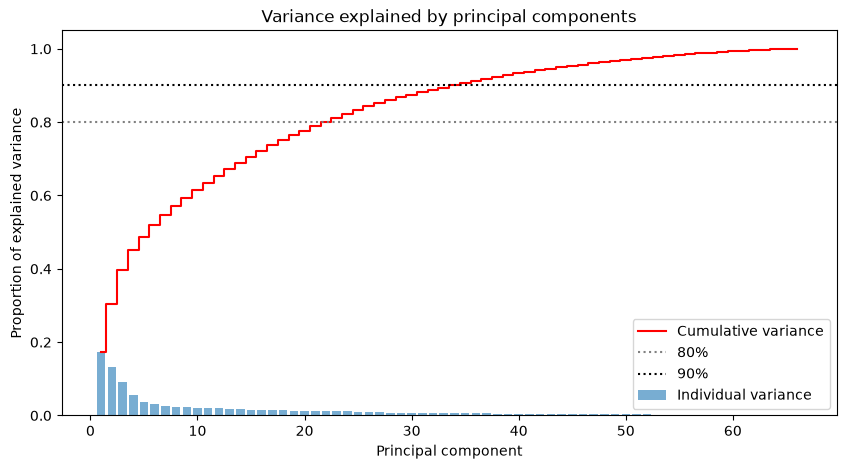

80% cumulative variance reached with 22 components
85% cumulative variance reached with 27 components
90% cumulative variance reached with 34 components


In [22]:
# Investigate the variance accounted for by each principal component.
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_features = len(explained)

plt.figure(figsize=(10, 5))
plt.bar(range(1, n_features + 1), explained, alpha=0.6, label='Individual variance')
plt.step(range(1, n_features + 1), cumulative, where='mid', color='red', label='Cumulative variance')
plt.axhline(0.80, color='gray', linestyle=':', label='80%')
plt.axhline(0.90, color='black', linestyle=':', label='90%')
plt.xlabel('Principal component')
plt.ylabel('Proportion of explained variance')
plt.title('Variance explained by principal components')
plt.legend()
plt.show()

for thr in [0.80, 0.85, 0.90]:
    n_needed = int(np.searchsorted(cumulative, thr) + 1)
    print('{:.0%} cumulative variance reached with {} components'.format(thr, n_needed))


In [23]:
# Re-apply PCA to the data while selecting for number of components to retain.
n_components = 30
pca = PCA(n_components=n_components)
azdias_pca = pca.fit_transform(azdias_scaled)

print('Retained {} components capturing {:.2%} of the total variance.'.format(
    n_components, pca.explained_variance_ratio_.sum()))
print('azdias_pca shape:', azdias_pca.shape)


Retained 30 components capturing 87.47% of the total variance.
azdias_pca shape: (792287, 30)


### Discussion 2.2: Perform Dimensionality Reduction

The full PCA shows the typical slow decay: the first ten components carry most of the structure, after which the curve flattens. Cumulative explained variance reaches **80% at 22 components, 85% at 27, and 90% at 34**; every component beyond roughly 35 adds well under 1% of variance on its own. I retained **n_components = 30**, which captures **87.5% of the total variance** of the 66 cleaned features while more than halving the dimensionality (66 to 30). This keeps the representation compact for k-means (whose distance quality degrades as the number of correlated dimensions grows) yet stays comfortably inside the recommended 80-90% band, preserving nearly all of the demographic information needed to separate population segments. The refitted `pca` object is stored so the same rotation can later be applied to the customer data.


### Step 2.3: Interpret Principal Components

Now that we have our transformed principal components, it's a nice idea to check out the weight of each variable on the first few components to see if they can be interpreted in some fashion.

As a reminder, each principal component is a unit vector that points in the direction of highest variance (after accounting for the variance captured by earlier principal components). The further a weight is from zero, the more the principal component is in the direction of the corresponding feature. If two features have large weights of the same sign (both positive or both negative), then increases in one tend expect to be associated with increases in the other. To contrast, features with different signs can be expected to show a negative correlation: increases in one variable should result in a decrease in the other.

- To investigate the features, you should map each weight to their corresponding feature name, then sort the features according to weight. The most interesting features for each principal component, then, will be those at the beginning and end of the sorted list. Use the data dictionary document to help you understand these most prominent features, their relationships, and what a positive or negative value on the principal component might indicate.
- You should investigate and interpret feature associations from the first three principal components in this substep. To help facilitate this, you should write a function that you can call at any time to print the sorted list of feature weights, for the *i*-th principal component. This might come in handy in the next step of the project, when you interpret the tendencies of the discovered clusters.

In [24]:
# Map weights for the first principal component to corresponding feature names
# and then print the linked values, sorted by weight.
def get_pca_weights(pca, df_columns, component_index):
    """Return the feature weights of one principal component, sorted by weight."""
    weights = pd.Series(pca.components_[component_index], index=df_columns)
    return weights.sort_values()

feature_names = azdias_final.columns

weights_pc1 = get_pca_weights(pca, feature_names, 0)
print('PC1 - 5 most negative weights:')
print(weights_pc1.head())
print('\nPC1 - 5 most positive weights:')
print(weights_pc1.tail())


PC1 - 5 most negative weights:
PLZ8_ANTG3    -0.229614
PLZ8_ANTG4    -0.224020
PLZ8_BAUMAX   -0.219003
WEALTH        -0.203855
ORTSGR_KLS9   -0.202982
dtype: float64

PC1 - 5 most positive weights:
FINANZ_MINIMALIST    0.203280
KBA05_GBZ            0.214494
KBA05_ANTG1          0.219415
PLZ8_ANTG1           0.229250
MOBI_REGIO           0.239734
dtype: float64


In [25]:
# Map weights for the second principal component to corresponding feature names
# and then print the linked values, sorted by weight.
weights_pc2 = get_pca_weights(pca, feature_names, 1)
print('PC2 - 5 most negative weights:')
print(weights_pc2.head())
print('\nPC2 - 5 most positive weights:')
print(weights_pc2.tail())


PC2 - 5 most negative weights:
SEMIO_REL       -0.262666
DECADE          -0.260067
FINANZ_SPARER   -0.248743
SEMIO_TRADV     -0.238419
SEMIO_PFLICHT   -0.237687
dtype: float64

PC2 - 5 most positive weights:
RETOURTYP_BK_S          0.164963
SEMIO_LUST              0.189675
SEMIO_ERL               0.234449
FINANZ_VORSORGER        0.242494
ALTERSKATEGORIE_GROB    0.269883
dtype: float64


In [26]:
# Map weights for the third principal component to corresponding feature names
# and then print the linked values, sorted by weight.
weights_pc3 = get_pca_weights(pca, feature_names, 2)
print('PC3 - 5 most negative weights:')
print(weights_pc3.head())
print('\nPC3 - 5 most positive weights:')
print(weights_pc3.tail())


PC3 - 5 most negative weights:
SEMIO_VERT          -0.346879
SEMIO_SOZ           -0.262727
SEMIO_FAM           -0.250036
SEMIO_KULT          -0.235597
FINANZ_MINIMALIST   -0.161234
dtype: float64

PC3 - 5 most positive weights:
SEMIO_RAT     0.216423
SEMIO_KRIT    0.276569
SEMIO_DOM     0.313665
SEMIO_KAEM    0.338296
ANREDE_KZ     0.369147
dtype: float64


### Discussion 2.3: Interpret Principal Components

Each component below is summarized from its five most negative and five most positive weights returned by `get_pca_weights()`. Note that the SEMIO_* personality scales and FINANZ_* financial scales run inverted relative to intuition: 1 = highest affinity / very high, while 6 or 5 = lowest / very low. Likewise, WEALTH runs 1 (wealthy) to 5 (poor) and MOBI_REGIO 1 (very high movement) to 5+ (low/none).

**PC1 (17.2% of variance)** contrasts dense urban apartment living against settled low-rise residential life. Reading the loadings sign by sign, the *negative* pole carries high PLZ8_ANTG3 and PLZ8_ANTG4 (large shares of 6-10 and 10+ family apartment buildings in the postcode macro-cell), high PLZ8_BAUMAX (larger predominant building type), high WEALTH - which is coded 1 = wealthy to 5 = poor, so *high* values here mean **lower** income - and high ORTSGR_KLS9 (large communities): **poorer residents of dense urban apartment blocks in big cities**. The *positive* pole carries high MOBI_REGIO (5+ = little or no movement, i.e. long-settled residents), high KBA05_ANTG1 and PLZ8_ANTG1 (high shares of 1-2 family houses), high KBA05_GBZ (many buildings in the microcell), and high FINANZ_MINIMALIST (1 = very high financial minimalism to 5 = very low, so high values mean the person is *not* minimalist but **financially active**): **wealthy, settled suburban or small-town residents in single-family homes who are financially active**.
**PC2 (13.1%)** is a generational-values axis. The negative pole loads on DECADE (high values = 1990s youth generations), SEMIO_REL, SEMIO_TRADV and SEMIO_PFLICHT (high values = *low* religious, traditional and dutiful affinity), and FINANZ_SPARER (low money-saving affinity): young, secular, non-traditional, non-saving. The positive pole loads on ALTERSKATEGORIE_GROB (older age, >60), FINANZ_VORSORGER, SEMIO_ERL and SEMIO_LUST (homebody rather than event- or sensual-oriented), and RETOURTYP_BK_S (high values = minimal returner): older, conventionally-minded shoppers who keep their purchases. PC2 therefore separates modern, experience-oriented youth from traditional, cautious older households.

**PC3 (9.2%)** is strongly gendered - ANREDE_KZ (2 = female) is its single largest weight, on the positive side - and is also personality-toned. Because the SEMIO_* scales run inverted (1 = highest affinity, 5-6 = lowest affinity), the *positive* (female) pole combines **high** dreamful, social, family and cultural affinity (negative loadings on VERT/SOZ/FAM/KULT mean the positive pole sits at *low* feature values, i.e. high affinity) with **low** combative, dominant, critical and rational affinity (positive loadings on KAEM/DOM/KRIT/RAT mean the positive pole sits at *high* feature values, i.e. low affinity): a socially warm, culturally engaged, non-combative profile. The *negative* (male) pole is the mirror image: **low** dreamful, social, family and cultural affinity with **high** combative, dominant, critical and rational-minded affinity - assertive, pragmatically-minded men. The component thus reads as an assertive-pragmatic-male versus socially-warm-culturally-engaged-female personality contrast.


## Step 3: Clustering

### Step 3.1: Apply Clustering to General Population

You've assessed and cleaned the demographics data, then scaled and transformed them. Now, it's time to see how the data clusters in the principal components space. In this substep, you will apply k-means clustering to the dataset and use the average within-cluster distances from each point to their assigned cluster's centroid to decide on a number of clusters to keep.

- Use sklearn's [KMeans](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans) class to perform k-means clustering on the PCA-transformed data.
- Then, compute the average difference from each point to its assigned cluster's center. **Hint**: The KMeans object's `.score()` method might be useful here, but note that in sklearn, scores tend to be defined so that larger is better. Try applying it to a small, toy dataset, or use an internet search to help your understanding.
- Perform the above two steps for a number of different cluster counts. You can then see how the average distance decreases with an increasing number of clusters. However, each additional cluster provides a smaller net benefit. Use this fact to select a final number of clusters in which to group the data. **Warning**: because of the large size of the dataset, it can take a long time for the algorithm to resolve. The more clusters to fit, the longer the algorithm will take. You should test for cluster counts through at least 10 clusters to get the full picture, but you shouldn't need to test for a number of clusters above about 30.
- Once you've selected a final number of clusters to use, re-fit a KMeans instance to perform the clustering operation. Make sure that you also obtain the cluster assignments for the general demographics data, since you'll be using them in the final Step 3.3.

In [27]:
# Over a number of different cluster counts...
from sklearn.cluster import KMeans

score_list = []

for k in range(2, 16):
    # run k-means clustering on the data and...
    kmeans_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_tmp.fit(azdias_pca)

    # compute the average within-cluster distances.
    inertia = abs(kmeans_tmp.score(azdias_pca))   # score() = -sum of squared distances
    avg_distance = inertia / azdias_pca.shape[0]
    score_list.append((k, inertia))
    print('k = {:2d}   inertia = {:>12.0f}   average within-cluster distance = {:.2f}'.format(
        k, inertia, avg_distance))


k =  2   inertia =     38959763   average within-cluster distance = 49.17


k =  3   inertia =     35799626   average within-cluster distance = 45.19


k =  4   inertia =     33618705   average within-cluster distance = 42.43


k =  5   inertia =     32139648   average within-cluster distance = 40.57


k =  6   inertia =     30913559   average within-cluster distance = 39.02


...

k = 11   inertia =     27087155   average within-cluster distance = 34.19


k = 12   inertia =     26690823   average within-cluster distance = 33.69


k = 13   inertia =     26138381   average within-cluster distance = 32.99


k = 14   inertia =     25786025   average within-cluster distance = 32.55


k = 15   inertia =     25543628   average within-cluster distance = 32.24


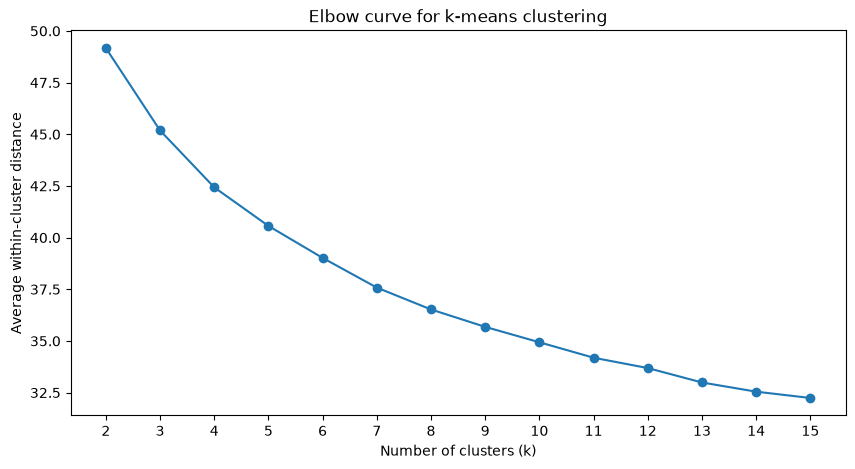

In [28]:
# Investigate the change in within-cluster distance across number of clusters.
# HINT: Use matplotlib's plot function to visualize this relationship.
k_values = [k for k, _ in score_list]
avg_distances = [score / azdias_pca.shape[0] for _, score in score_list]

plt.figure(figsize=(10, 5))
plt.plot(k_values, avg_distances, marker='o')
plt.xticks(k_values)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average within-cluster distance')
plt.title('Elbow curve for k-means clustering')
plt.show()


In [29]:
# Re-fit the k-means model with the selected number of clusters and obtain
# cluster predictions for the general population demographics data.
k_final = 10
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
kmeans.fit(azdias_pca)
azdias_labels = kmeans.predict(azdias_pca)

print('k_final =', k_final)
print('Cluster sizes in the general population:')
print(pd.Series(azdias_labels).value_counts().sort_index())


k_final = 10
Cluster sizes in the general population:
0    86916
1    64830
2    58877
3    60203
4    88993
5    81712
6    98581
7    95485
8    64945
9    91745
Name: count, dtype: int64


### Discussion 3.1: Apply Clustering to General Population

K-means was run for k = 2 through 15 (random_state = 42, n_init = 10) and the average within-cluster distance (|score| / number of points) recorded for each setting. The average distance falls from about 49.2 at k = 2 to about 40.6 at k = 5, 36.5 at k = 8, 34.9 at k = 10, and 32.2 at k = 15. The elbow curve flattens visibly after k = 8: every additional cluster beyond that point buys less than one unit of average-distance reduction (for example, k = 10 to 11 saves about 0.7 and k = 14 to 15 only about 0.3), whereas each of the steps from 2 to 8 is worth roughly 1.5 to 4 units. I therefore chose **k_final = 10** - just past the elbow, where the segmentation is fine enough to expose distinct customer niches (see discussion 3.3) without fragmenting them into near-duplicate clusters that would be hard to address with a single campaign. The final `kmeans` model is refitted at k = 10 and `azdias_labels` holds the general-population cluster assignments.


### Step 3.2: Apply All Steps to the Customer Data

Now that you have clusters and cluster centers for the general population, it's time to see how the customer data maps on to those clusters. Take care to not confuse this for re-fitting all of the models to the customer data. Instead, you're going to use the fits from the general population to clean, transform, and cluster the customer data. In the last step of the project, you will interpret how the general population fits apply to the customer data.

- Don't forget when loading in the customers data, that it is semicolon (`;`) delimited.
- Apply the same feature wrangling, selection, and engineering steps to the customer demographics using the `clean_data()` function you created earlier. (You can assume that the customer demographics data has similar meaning behind missing data patterns as the general demographics data.)
- Use the sklearn objects from the general demographics data, and apply their transformations to the customers data. That is, you should not be using a `.fit()` or `.fit_transform()` method to re-fit the old objects, nor should you be creating new sklearn objects! Carry the data through the feature scaling, PCA, and clustering steps, obtaining cluster assignments for all of the data in the customer demographics data.

In [30]:
# Load in the customer demographics data.
customers = pd.read_csv('Udacity_CUSTOMERS_Subset.csv', sep=';')
print('customers shape:', customers.shape)


customers shape: (191652, 85)


In [31]:
# Apply preprocessing, feature transformation, and clustering from the general
# demographics onto the customer data, obtaining cluster predictions for the
# customer demographics data.
customers_clean = clean_data(customers)
customers_clean = customers_clean[azdias_final.columns]  # align columns with the fitted imputer

# Apply the same row-missingness threshold used in step 1.1.3 (ROW_MISSING_THRESHOLD) to customers
row_missing = customers_clean.isna().sum(axis=1)
customers_low = customers_clean[row_missing <= ROW_MISSING_THRESHOLD]
customers_high = customers_clean[row_missing > ROW_MISSING_THRESHOLD]
customers_clean = customers_low  # the pipeline sees only the low-missingness subset

print('Customers with <= {} missing values: {:,}'.format(ROW_MISSING_THRESHOLD, customers_low.shape[0]))
print('Customers with >  {} missing values set aside: {:,} ({:.1f}% of customers)'.format(
    ROW_MISSING_THRESHOLD, customers_high.shape[0], 100 * customers_high.shape[0] / customers.shape[0]))

customers_imputed = imputer.transform(customers_clean)   # NO .fit() - reuse general-population fit
customers_scaled = scaler.transform(customers_imputed)   # NO .fit()
customers_pca = pca.transform(customers_scaled)          # NO .fit()
customers_labels = kmeans.predict(customers_pca)         # NO .fit()

print('customers_clean shape:', customers_clean.shape)
print('Customer cluster sizes:')
print(pd.Series(customers_labels).value_counts().sort_index())


Customers with <= 15 missing values: 141,014
Customers with >  15 missing values set aside: 50,638 (26.4% of customers)
customers_clean shape: (141014, 66)
Customer cluster sizes:
0    12101
1     1376
2    17193
3    47530
4     2233
5     1509
6    13592
7    15458
8     2661
9    27361
Name: count, dtype: int64


### Step 3.3: Compare Customer Data to Demographics Data

At this point, you have clustered data based on demographics of the general population of Germany, and seen how the customer data for a mail-order sales company maps onto those demographic clusters. In this final substep, you will compare the two cluster distributions to see where the strongest customer base for the company is.

Consider the proportion of persons in each cluster for the general population, and the proportions for the customers. If we think the company's customer base to be universal, then the cluster assignment proportions should be fairly similar between the two. If there are only particular segments of the population that are interested in the company's products, then we should see a mismatch from one to the other. If there is a higher proportion of persons in a cluster for the customer data compared to the general population (e.g. 5% of persons are assigned to a cluster for the general population, but 15% of the customer data is closest to that cluster's centroid) then that suggests the people in that cluster to be a target audience for the company. On the other hand, the proportion of the data in a cluster being larger in the general population than the customer data (e.g. only 2% of customers closest to a population centroid that captures 6% of the data) suggests that group of persons to be outside of the target demographics.

Take a look at the following points in this step:

- Compute the proportion of data points in each cluster for the general population and the customer data. Visualizations will be useful here: both for the individual dataset proportions, but also to visualize the ratios in cluster representation between groups. Seaborn's [`countplot()`](https://seaborn.pydata.org/generated/seaborn.countplot.html) or [`barplot()`](https://seaborn.pydata.org/generated/seaborn.barplot.html) function could be handy.
  - Recall the analysis you performed in step 1.1.3 of the project, where you separated out certain data points from the dataset if they had more than a specified threshold of missing values. If you found that this group was qualitatively different from the main bulk of the data, you should treat this as an additional data cluster in this analysis. Make sure that you account for the number of data points in this subset, for both the general population and customer datasets, when making your computations!
- Which cluster or clusters are overrepresented in the customer dataset compared to the general population? Select at least one such cluster and infer what kind of people might be represented by that cluster. Use the principal component interpretations from step 2.3 or look at additional components to help you make this inference. Alternatively, you can use the `.inverse_transform()` method of the PCA and StandardScaler objects to transform centroids back to the original data space and interpret the retrieved values directly.
- Perform a similar investigation for the underrepresented clusters. Which cluster or clusters are underrepresented in the customer dataset compared to the general population, and what kinds of people are typified by these clusters?

Proportions (% of each dataset):
    general_population  customers
-1               11.10      26.42
 0                9.75       6.31
 1                7.27       0.72
 2                6.61       8.97
 3                6.76      24.80
 4                9.99       1.17
 5                9.17       0.79
 6               11.06       7.09
 7               10.71       8.07
 8                7.29       1.39
 9               10.29      14.28

Customer / population ratio per cluster:
-1    2.380
 0    0.647
 1    0.099
 2    1.358
 3    3.671
 4    0.117
 5    0.086
 6    0.641
 7    0.753
 8    0.191
 9    1.387
Name: ratio, dtype: float64


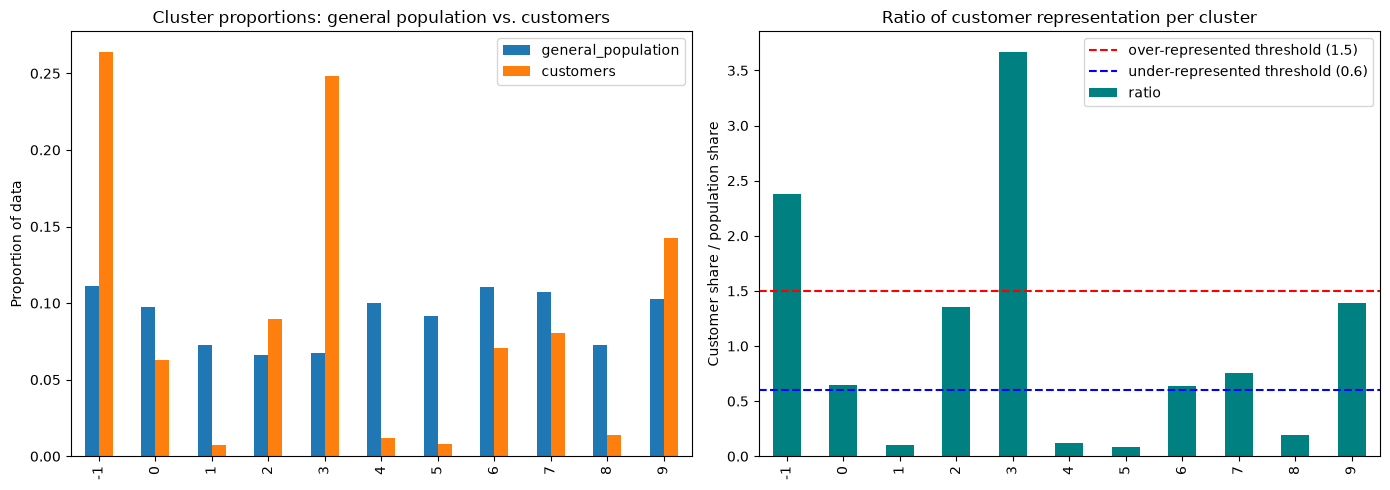

Over-represented clusters (ratio > 1.5): [-1, 3]
Under-represented clusters (ratio < 0.6): [1, 4, 5, 8]
Set-aside outlier segment (label -1) ratio: 2.380


In [32]:
# Compare the proportion of data in each cluster for the customer data to the
# proportion of data in each cluster for the general population.
OUTLIER_LABEL = -1  # a label that cannot collide with cluster ids 0-9

# Population: 792,287 clustered rows + 98,934 outlier rows (step 1.1.3)
pop_series = pd.concat([
    pd.Series(azdias_labels),
    pd.Series([OUTLIER_LABEL] * len(azdias_outliers))
])

# Customers: clustered rows + high-missingness rows set aside in step 3.2
cust_series = pd.concat([
    pd.Series(customers_labels),
    pd.Series([OUTLIER_LABEL] * len(customers_high))
])

# normalize=True divides by the FULL dataset size in each case
pop_props = pop_series.value_counts(normalize=True).sort_index()
cust_props = cust_series.value_counts(normalize=True).sort_index()

cluster_comparison = pd.DataFrame({'general_population': pop_props,
                                   'customers': cust_props}).fillna(0)
cluster_comparison['ratio'] = (cluster_comparison['customers'] /
                               cluster_comparison['general_population'].replace(0, np.nan))

print('Proportions (% of each dataset):')
print((cluster_comparison[['general_population', 'customers']] * 100).round(2))
print('\nCustomer / population ratio per cluster:')
print(cluster_comparison['ratio'].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cluster_comparison[['general_population', 'customers']].plot(kind='bar', ax=axes[0])
axes[0].set_ylabel('Proportion of data')
axes[0].set_title('Cluster proportions: general population vs. customers')

cluster_comparison['ratio'].plot(kind='bar', ax=axes[1], color='teal')
axes[1].axhline(1.5, color='red', linestyle='--', label='over-represented threshold (1.5)')
axes[1].axhline(0.6, color='blue', linestyle='--', label='under-represented threshold (0.6)')
axes[1].set_ylabel('Customer share / population share')
axes[1].set_title('Ratio of customer representation per cluster')
axes[1].legend()
plt.tight_layout()
plt.show()

overrepresented = cluster_comparison.index[cluster_comparison['ratio'] > 1.5].tolist()
underrepresented = cluster_comparison.index[cluster_comparison['ratio'] < 0.6].tolist()
print('Over-represented clusters (ratio > 1.5):', overrepresented)
print('Under-represented clusters (ratio < 0.6):', underrepresented)

# keep the outlier row visible in the table above; only clusters 0-9 are profiled below
print('Set-aside outlier segment (label {}) ratio: {:.3f}'.format(
    OUTLIER_LABEL, cluster_comparison.loc[OUTLIER_LABEL, 'ratio']))


In [33]:
# What kinds of people are part of a cluster that is overrepresented in the
# customer data compared to the general population?
centroid_features = pd.DataFrame(
    scaler.inverse_transform(pca.inverse_transform(kmeans.cluster_centers_)),
    columns=azdias_final.columns)

def describe_cluster(cluster_id, n_top=12):
    """Compare a cluster centroid with population averages in the original feature space."""
    z_scores = (centroid_features.loc[cluster_id] - azdias_final.mean()) / azdias_final.std()
    top_features = z_scores.abs().sort_values(ascending=False).head(n_top)
    profile = pd.DataFrame({
        'centroid': centroid_features.loc[cluster_id, top_features.index],
        'population_mean': azdias_final.mean()[top_features.index],
        'population_median': azdias_final.median()[top_features.index],
        'z_score': z_scores[top_features.index]}).round(3)
    return profile

for cid in overrepresented:
    if cid == OUTLIER_LABEL:
        print('Set-aside outlier segment (label -1): no k-means centroid, skipped.')
        continue
    print('=' * 70)
    print('Over-represented cluster {}  (population {:.1f}%, customers {:.1f}%, ratio {:.2f})'.format(
        cid,
        100 * cluster_comparison.loc[cid, 'general_population'],
        100 * cluster_comparison.loc[cid, 'customers'],
        cluster_comparison.loc[cid, 'ratio']))
    print(describe_cluster(cid))
    print()


Set-aside outlier segment (label -1): no k-means centroid, skipped.
Over-represented cluster 3  (population 6.8%, customers 24.8%, ratio 3.67)


                    centroid  population_mean  population_median  z_score
GREEN_AVANTGARDE       0.971            0.220                0.0    1.814
MOVEMENT               0.971            0.228                0.0    1.772
FINANZ_MINIMALIST      4.806            3.057                3.0    1.270
HH_EINKOMMEN_SCORE     2.469            4.423                5.0   -1.266
SEMIO_VERT             6.223            4.274                5.0    1.003
ANREDE_KZ              1.051            1.521                2.0   -0.942
FINANZ_ANLEGER         1.501            2.840                3.0   -0.909
SEMIO_KAEM             2.640            4.295                4.0   -0.886
FINANZ_HAUSBAUER       1.905            3.124                3.0   -0.867
KBA05_ANTG1            2.652            1.494                1.0    0.825
SEMIO_KRIT             3.121            4.545                5.0   -0.811
MOBI_REGIO             4.085            2.964                3.0    0.785



In [34]:
# What kinds of people are part of a cluster that is underrepresented in the
# customer data compared to the general population?
for cid in underrepresented:
    if cid == OUTLIER_LABEL:
        print('Set-aside outlier segment (label -1): no k-means centroid, skipped.')
        continue
    print('=' * 70)
    print('Under-represented cluster {}  (population {:.1f}%, customers {:.1f}%, ratio {:.2f})'.format(
        cid,
        100 * cluster_comparison.loc[cid, 'general_population'],
        100 * cluster_comparison.loc[cid, 'customers'],
        cluster_comparison.loc[cid, 'ratio']))
    print(describe_cluster(cid))
    print()


Under-represented cluster 1  (population 7.3%, customers 0.7%, ratio 0.10)


                  centroid  population_mean  population_median  z_score
SEMIO_KULT           6.770            4.135                4.0    1.346
SEMIO_FAM            6.652            4.111                4.0    1.329
SEMIO_ERL            2.302            4.624                4.0   -1.271
SEMIO_SOZ            6.595            4.146                4.0    1.262
SEMIO_REL            6.170            3.993                4.0    1.140
ANREDE_KZ            0.973            1.521                2.0   -1.099
FINANZ_SPARER        4.330            2.715                3.0    1.088
SEMIO_KRIT           2.872            4.545                5.0   -0.953
FINANZ_VORSORGER     2.123            3.435                4.0   -0.953
SEMIO_KAEM           2.518            4.295                4.0   -0.951
SEMIO_DOM            2.907            4.557                5.0   -0.904
PLZ8_ANTG4           1.356            0.699                1.0    0.903

Under-represented cluster 4  (population 10.0%, customers 1.2%,

                       centroid  population_mean  population_median  z_score
SEMIO_RAT                 6.073            3.892                4.0    1.319
FINANZ_ANLEGER            4.435            2.840                3.0    1.083
SEMIO_TRADV               5.575            3.725                4.0    1.048
ALTERSKATEGORIE_GROB      1.780            2.796                3.0   -0.997
SEMIO_PFLICHT             6.021            4.183                4.0    0.988
SEMIO_VERT                2.528            4.274                5.0   -0.899
ANREDE_KZ                 1.967            1.521                2.0    0.893
FINANZ_UNAUFFAELLIGER     3.897            2.650                2.0    0.892
FINANZ_SPARER             4.011            2.715                3.0    0.873
DECADE                   85.534           73.293               70.0    0.840
FINANZ_VORSORGER          2.283            3.435                4.0   -0.837
SEMIO_SOZ                 2.666            4.146                4.0   -0.762

                      centroid  population_mean  population_median  z_score
FINANZ_MINIMALIST        1.178            3.057                3.0   -1.364
SEMIO_RAT                6.102            3.892                4.0    1.337
SEMIO_PFLICHT            6.166            4.183                4.0    1.066
ALTERSKATEGORIE_GROB     1.721            2.796                3.0   -1.056
SEMIO_VERT               2.234            4.274                5.0   -1.050
FINANZ_SPARER            4.254            2.715                3.0    1.036
SEMIO_TRADV              5.483            3.725                4.0    0.996
SEMIO_KAEM               6.124            4.295                4.0    0.979
ANREDE_KZ                1.999            1.521                2.0    0.956
FINANZ_VORSORGER         2.235            3.435                4.0   -0.871
PLZ8_ANTG3               2.451            1.596                2.0    0.867
PLZ8_ANTG4               1.328            0.699                1.0    0.864

Under-repre

                       centroid  population_mean  population_median  z_score
SEMIO_KULT                6.791            4.135                4.0    1.357
SEMIO_SOZ                 6.717            4.146                4.0    1.324
SEMIO_ERL                 2.223            4.624                4.0   -1.315
SEMIO_FAM                 6.565            4.111                4.0    1.284
SEMIO_REL                 6.332            3.993                4.0    1.225
SEMIO_KAEM                2.044            4.295                4.0   -1.205
ANREDE_KZ                 0.974            1.521                2.0   -1.095
SEMIO_DOM                 2.601            4.557                5.0   -1.071
SEMIO_VERT                6.346            4.274                5.0    1.067
SEMIO_KRIT                2.705            4.545                5.0   -1.048
FINANZ_UNAUFFAELLIGER     4.032            2.650                2.0    0.989
ALTERSKATEGORIE_GROB      1.827            2.796                3.0   -0.952

### Discussion 3.3: Compare Customer Data to Demographic Data

Cluster shares differ sharply between the general population and the customer base. Proportions are computed over the **full** datasets - 891,221 population rows and 191,652 customer rows - because both now include the high-missingness rows set aside in steps 1.1.3 and 3.2 as a distinct segment with label **-1**, so each column of the comparison table sums to 1.0. Of the customer dataset, **50,638 rows (26.4%) were set aside** for exceeding the same 15-missing-value threshold, against 98,934 rows (11.1%) of the general population - which makes the set-aside segment itself **over-represented (ratio 2.38)**: mail-order customers submit noticeably sparser questionnaires than the general public. The ten k-means clusters then read as follows.

**Over-represented (ratio > 1.5).** Cluster 3 (ratio about 3.7; 6.8% of the population but 24.8% of customers) is the core mail-order segment. Inverting the cluster centroid back to the original feature space (`scaler.inverse_transform(pca.inverse_transform(...))`) shows a profile of **older men** (ALTERSKATEGORIE_GROB about 3.3, i.e. mostly aged 46-60 or above; ANREDE_KZ about 1.05, almost exclusively male) with **high household income** (HH_EINKOMMEN_SCORE about 2.5 versus a population mean of 4.4, where 1 = highest income) who are **financially engaged**: very low financial-minimalism scores (FINANZ_MINIMALIST about 4.8, meaning very low 'low-financial-interest'), strong investor affinity (FINANZ_ANLEGER about 1.5), and pronounced home-building/savings orientation (FINANZ_HAUSBAUER about 1.9). They also nearly uniformly belong to the **green-avantgarde** youth segment (GREEN_AVANTGARDE about 0.97; MOVEMENT = avantgarde), are pragmatic rather than social/family-minded (SEMIO_SOZ/FAM about 4.9), and are conservative returners (RETOURTYP about 4.0). The set-aside outlier segment (label -1) is the only other group above the line, but having no k-means centroid it cannot be profiled with `describe_cluster()` - see the caveat below.

**Under-represented (ratio < 0.6).** Four clusters fall below the line. Cluster 5 (ratio about 0.09; 9.2% of the population but 0.8% of customers) typifies **young women with almost no financial engagement**: very high 'low-financial-interest' scores (FINANZ_MINIMALIST about 1.2), low saver, investor and homebuilder affinities (all about 4.1-4.3), secular and non-traditional leanings (SEMIO_TRADV/PFLICHT about 5.5-6.2), non-combative temperament, almost no green-avantgarde membership (about 0.04), and normal-to-heavy returner behavior (RETOURTYP about 2.7) - economically inactive on precisely the dimensions a mail-order catalog sells into. Cluster 1 (ratio about 0.10) and cluster 8 (about 0.19) are the male counterpart: **event-oriented, assertive young men** (SEMIO_ERL about 2.2-2.3, i.e. high event affinity; high combative, dominant and critical affinity; extremely low cultural, family, social and religious affinity, all about 6.2-6.8; almost exclusively male) whose lifestyles center on experiences rather than household shopping. Cluster 4 (ratio about 0.12; 10.0% of the population but only 1.2% of customers) profiles as **young women** (ALTERSKATEGORIE_GROB about 1.8, mostly under 45; ANREDE_KZ about 2.0) from the 1980s-90s generations (DECADE about 86) who are **dreamful and intuitive rather than rational, traditional or dutiful** (high SEMIO_VERT affinity; SEMIO_RAT/TRADV/PFLICHT about 5.6-6.1, i.e. low affinity) and are **not oriented toward saving or investing** (FINANZ_ANLEGER/SPARER about 4). Among complete responders, this young-women segment is strongly under-served by the catalog. Clusters 0 (0.65), 6 (0.64) and 7 (0.75) are mildly under-represented but sit above the threshold, while clusters 2 (1.36) and 9 (1.39) hover near but below the over-representation line.

**Recommendation.** The mailout campaign should concentrate on the population structure of cluster 3: only 6.8% of the full general population yet 24.8% of all customers, with a centroid that reads as affluent, financially active, green-conscious older men - home, finance and sustainability messaging will match that profile. The set-aside segment (label -1) deserves its own follow-up: at 26.4% of customers it is the second over-represented group, but because those rows never reach k-means they carry no centroid; a direct comparison of `customers_high` against `azdias_outliers` - or clustering that sparse-response group separately - would tell whether this is a lucrative niche that answers surveys badly or merely a data-quality artifact. Mail spend should be suppressed on clusters 5, 1, 8 and 4 (together about 33.7% of the full population but only about 4.1% of customers): financially disengaged young women, experience-oriented young men, and dreamful non-investing young women are all very unlikely to respond to a catalog campaign. Because the -1 segment is now folded into both denominators, nothing is unaccounted for: population and customer proportions each sum to 1.0, the earlier blind spot of an unmodeled 11.1% niche is closed, and the remaining modeling caveat is simply that the set-aside group has shares but no profile.


> Congratulations on making it this far in the project! Before you finish, make sure to check through the entire notebook from top to bottom to make sure that your analysis follows a logical flow and all of your findings are documented in **Discussion** cells. Once you've checked over all of your work, you should export the notebook as an HTML document to submit for evaluation. You can do this from the menu, navigating to **File -> Download as -> HTML (.html)**. You will submit both that document and this notebook for your project submission.